<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Predicting Lung Nodule Malignancy from CT Data
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What data do we have?
  </h3>

  <p>
  
| Dataset | What it contains | How we use it |
|---|---|---|
| LNDb train | 236 CT scans, with 1219 unique findings (768 nodules), segmentation masks for nodules >= 3 mm | Main training data |
| LNDb test | 58 CT scans and 2900 candidates (50 per CT) with only a centroid | Inference only. Every candidate is predicted as if it were a nodule |
| LIDC IDRI | 1010 patients, 1018 CT series, up to four readings per nodule | Annotations through `pylidc`; patches cut from the DICOM files; used to train the size model |
  </p>
  <p>
  Malignancy is evaluated in LNDb's file <strong>'chars_trainNodules.csv'</strong>.
  </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Which files to consider? And which to discard?
  </h3>

  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Kept:
      <ul style="padding-left: 20px; margin-bottom: 20px;">
      <li style="margin-bottom: 8px;">The merged findings file <strong>'trainNodules_gt.csv'</strong>. The unit of analysis is the nodule, not the reading, because one nodule can be read by up to three radiologists and counting it three times would leak information which is a crucial error we made sure not to make.</li>
      <li style="margin-bottom: 8px;"><strong>'chars_trainNodules.csv'</strong> for the malignancy ratings, <strong>'LNDbAcqParams.csv'</strong> for scanner information, and the masks for nodules of 3 mm or more.</li>
      <li style="margin-bottom: 8px;">The official LNDb folds <strong>'trainFolds.csv'</strong>, split by CT, used to confirm the final choice on splits that played no part in it.</li>
      </ul>
    </li>
    <li style="margin-bottom: 8px;">Dropped:
      <ul style="padding-left: 20px; margin-bottom: 20px;">
        <li style="margin-bottom: 8px;">The per patient diagnosis file of LIDC. It says whether a patient has cancer but not which nodule is the malignant one, so using it as a label would give every nodule of that patient the same wrong answer. Therefore, we did not consider it useful for our main goal.</li>
        <li style="margin-bottom: 8px;">Fleischner files and medical reports. Fleischner is a follow up recommendation, not malignancy, and reports do not exist for the test scans.</li>
        <li style="margin-bottom: 8px;">The original <strong>'.rar'</strong> archives, the X ray series of LIDC (DX and CR) and the macOS <strong>'._*'</strong> files.</li>
        </ul>
    </li>
    <li style="margin-bottom: 8px;">Practical Notes:</li>
      <ul style="padding-left: 20px; margin-bottom: 20px;">
        <li style="margin-bottom: 8px;">In the LNDb files, Malignancy is averaged in <strong>'allNods.csv'</strong>.</li>
      </ul>
    </li>
  </ol>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Key Findings in the Literature
  </h3>

  <p>
  <strong> Size alone explains a lot -</strong> Baltatzis et al. (2021) show that a baseline that only uses nodule diameter reaches 83% to 85% accuracy on LIDC, and that the way labels are aggregated can matter more than the model. Mean and median aggregation give 1010 and 848 usable nodules respectively. We will always report a diameter only baseline and use that for any comparision needed.
  </p>
  <p>
  <strong>Splits must respect patients -</strong> Causey et al. criticise works that mix nodules of the same patient across training and validation. Nodules from one scan share scanner, protocol and anatomy, so we we decided to always validate by CT scan.
  </p>
  <p>
  <strong>Tools -</strong> PyRadiomics (van Griethuysen et al., 2017) is our feature extractor and the IBSI work (Zwanenburg et al., 2020) is the reference for feature definitions. We use a fixed bin width and resample to 1 mm isotropic voxels.
  </p>
  <p>
  <strong>Domain shift -</strong> LNDb comes from one hospital with three Siemens scanner models, while LIDC is multi centre and multi vendor. LNDb was designed as an external set for models trained on LIDC. We first rely on resampling and normalisation, and only consider ComBat harmonisation (Orlhac et al., 2022) if the features show a clear scanner effect.
  </p>
  <p>
  <strong>Pretrained features -</strong> The foundation model of Pai et al. (2024) only needs the lesion centroid, exactly what our test file has. It is an option for later, since our team decided not to use deep learning for now.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Decisions
  </h3>

  | Decision | Choice | Why |
|----|----|----|
| Unit of analysis | Unique nodule | Avoids counting the same nodule several times |
| Training rows | Nodules with malignancy rating only | Non-nodules have no rating and only add noise |
| Training label | Mean of the non zero ratings, rounded half up | Keeps the 1 to 5 scale |
| Region of interest | Same procedure from the centroid in training and test | The test set has only coordinates. Masks serve only to check our segmentation and robustness of features |
| Features | 21 handcrafted features and 9 sphere features; PyRadiomics analysed (IBSI configuration, ICC) but not used because it did not help | Simple, explainable, robust |
| Size | Learned from the radiologists' diameters (exist only in training) | Segmentation measures size poorly; learning using privileged information (Vapnik and Vashist, 2009) |
| Model | Ordinal logistic regression with an L2 penalty | Ordered classes, few parameters (McCullagh, 1980) |
| Decision rule | Most probable class after a partial correction for class frequencies (power 0.5 for the rarest classes) | Balances the four competition metrics (Saerens et al., 2002) |
| LIDC | Trains the size model only | Physical size is comparable between datasets, but not the rating due to context change. In the classifier LIDC made results worse |
| Validation | Grouped by CT/patient, stratified, repeated; intervals by resampling CTs; confirmation on new seeds and on the official folds | Leakage control (Kapoor and Narayanan, 2023), small sample error bars (Varoquaux, 2018), selection bias (Cawley and Talbot, 2010) |
| Metrics | The four competition metrics plus a composite (BA + F1 + QWK - MAE), within one class, sensitivity for ratings 4 and 5 | The ranking is a mean rank; the extra metrics are for our decisions and the report |

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import SimpleITK as sitk
import random
import time
from multiprocessing import Pool
from scipy import ndimage as ndi
from skimage.measure import marching_cubes, mesh_surface_area
import logging
from radiomics import featureextractor
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score, mean_absolute_error, confusion_matrix
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import ast
import math
import pydicom
from scipy.sparse.csgraph import connected_components
import inspect
import shutil
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectKBest, f_regression

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Patches
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Cutting 3D Patches (LNDb)
  </h3>
  <p>
  A patch is a cube of 64 mm around a center given in world coordinates (mm). It is resampled to 1 mm voxels, so the array has 64 x 64 x 64 voxels and the centre falls exactly on voxel (32, 32, 32). The values are raw Hounsfield units (int16). The array axes are (z, y, x) and they are aligned with the world axes, whatever the tilt of the CT, so every patch is oriented in the same way. Every feature is then measured in three dimensions inside this cube: the segmentation, size, shape, density, the ring around the nodule the sphere features and the radiomic features.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Why 3D Patches?
  </h3>
  <p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">A nodule and a vessel can look the same in one slice. A vessel cut across looks like a small round blob on an axial slice, exactly like a nodule. Only along the third axis does it reveals itself as a tube. Our segmentation relies on this: it removes the parts of the region that extend away from the nodule, which are mostly vessels and pleura. The detection literature shows the same effect. Setio et al. (2016) found that combining several views of a candidate works better than a single view, and Dou et al. (2017) showed that 3D context helps to tell nodules from false positives. Although thee studies use neural networks, the point still holds for any method since the third dimension carries information that a slice does not.</li>
    <li style="margin-bottom: 8px;">Size is the strongest predictor, and it is best measured as a volume. The Fleischner Society guidelines give their size thresholds both as diameters and as volumes (MacMahon et al., 2017). Volume, sphericity, elongation and flatness only exist in 3D, and a diameter measured on one slice depends on which slice is chosen.</li>
    <li style="margin-bottom: 8px;">Radiomic features are defined in 3D. The Image Biomarker Standardisation Initiative defines its shape and texture features on volumes and recommends isotropic voxels before computing them (Zwanenburg et al., 2020). Texture features change when the voxel size changes (Shafiq-ul-Hassan et al., 2017). Resampling every patch to 1 mm in all directions makes the features comparable between scans with different pixel sizes and slice spacings.</li>
    <li style="margin-bottom: 8px;">Almost all LNDb scans have 1 mm slices, so a 1 mm cube adds very little interpolation. The test file gives each candidate as a point in world coordinates (x, y, z), so a cube around that point is the natural unit. The cube is also what the LNDb authors distribute (the script getNoduleCubes.py cuts cubes of 51 mm). Recent work does the same: the foundation model of Pai et al. (2024) takes 50 mm cubes at 1 mm around the lesion centre.</li>
  </ul>
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   And why 64mm?
  </h3>

  <p>
  The largest rated LNDb nodule measures about 31 mm. A 64 mm cube holds it with room for the surrounding tissue (vessels, pleura, chest wall), which the ring features and the vessel removal need. Our choice for the specific number of 64 mm is a practical choice, close to the 50 to 51 mm used by the references.
  </p>
  <p>
  The following code cuts 3D patches around nodule centres, with the same procedure for training and test.
  </p>

</div>


In [ ]:
PATCH_SIZE = 64                        # Voxels per side
SPACING_MM = 1.0                       # Voxel size of the patch
CENTRE_INDEX = PATCH_SIZE // 2         # Voxel that holds the centre: 32
AIR_HU = -1024                         # Value used outside the CT, the floor of the usual HU normalisation

REPO_ROOT = Path.cwd().parent          # Root of our project's repository in the machine.
DATA_DIR = Path(os.environ.get("MASS_DATA_DIR", REPO_ROOT / "data")) #where our 'data' folder is located
LNDB_DIR = DATA_DIR / "LNDb"           # LNDb dataset location
PATCHES_DIR = DATA_DIR / "patches"     # Patches location

def find_ct_files(): # Maps each LNDb CT id to its .mhd file, in the training and test folders
    files = {}
    for pattern in ("data/data[0-5]/LNDb-*.mhd", "data/testdata[01]/LNDb-*.mhd"):
        for path in LNDB_DIR.glob(pattern):
            files[int(path.stem.split("-")[1])] = path
    return files

def load_findings(split): # Findings of the split with their centre in world coordinates (mm)
    if split == "train": table = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
    else: table = pd.read_csv(LNDB_DIR / "testNodules.csv")
    return table[["LNDbID", "FindingID", "x", "y", "z"]]


def centre_is_inside(image, centre_mm): # Gives True when the physical point falls inside the volume of the image
    index = np.array(image.TransformPhysicalPointToContinuousIndex(tuple(float(v) for v in centre_mm)))
    size = np.array(image.GetSize())
    return bool(np.all(index >= -0.5) and np.all(index <= size - 0.5))

def extract_patch(image, centre_mm, interpolator=sitk.sitkLinear, outside_value=AIR_HU): # Cuts 64mm cube around a world point
    #SimpleITK looks up each voxel in the CT using origin, spacing and direction of the CT, so a tilted CT is handled correctly.
    origin = np.asarray(centre_mm, dtype=float) - CENTRE_INDEX * SPACING_MM
    resampler = sitk.ResampleImageFilter()
    resampler.SetSize([PATCH_SIZE] * 3)
    resampler.SetOutputSpacing([SPACING_MM] * 3)
    resampler.SetOutputDirection(tuple(np.eye(3).ravel()))
    resampler.SetOutputOrigin(tuple(origin))
    resampler.SetInterpolator(interpolator)
    resampler.SetOutputPixelType(sitk.sitkFloat32)
    resampler.SetDefaultPixelValue(float("nan"))                  # Marks the voxels that fall outside the CT

    patch = sitk.GetArrayFromImage(resampler.Execute(image))      # The numpy order is (z, y, x)
    outside = np.isnan(patch)
    patch[outside] = outside_value                                # Points outside the CT get outside_value
    return np.rint(patch).astype(np.int16), float(outside.mean()) # Returns (patch, outside_fraction); outside_fraction says how many voxels they are.

def cut_scan_patches(ct_id, ct_path, findings, split, out_dir): # Cuts and saves the patches of every finding of one CT. Returns one row per finding
    image = sitk.ReadImage(str(ct_path))
    rows = []
    for finding in findings.itertuples():
        patch_id = f"LNDb-{ct_id:04d}_f{finding.FindingID:03d}"
        centre = (finding.x, finding.y, finding.z)
        row = {"patch_id": patch_id, "split": split, "ct_id": ct_id, "finding_id": finding.FindingID,
               "x_mm": finding.x, "y_mm": finding.y, "z_mm": finding.z,
               "status": "ok", "outside_fraction": np.nan, "hu_min": np.nan, "hu_max": np.nan, "file": ""}
        try:
            index = image.TransformPhysicalPointToContinuousIndex(tuple(float(v) for v in centre))
            row.update(ct_index_x=index[0], ct_index_y=index[1], ct_index_z=index[2])
            if not centre_is_inside(image, centre):
                row["status"] = "centre_outside_volume"
            else:
                patch, outside_fraction = extract_patch(image, centre)
                relative_path = f"{split}/{patch_id}.npy"
                np.save(out_dir / relative_path, patch)
                row.update(outside_fraction=outside_fraction, hu_min=int(patch.min()), hu_max=int(patch.max()),
                           file=relative_path)
        except Exception as error:              
            row["status"] = f"error: {error}"
        rows.append(row)
    return rows

def cut_lndb_patches(split, limit_cts=None, overwrite=False, out_dir=PATCHES_DIR): # Processes one CT at a time (to keep the memory low) and writes one file per CT
    ct_files = find_ct_files()
    findings = load_findings(split)
    (out_dir / split).mkdir(parents=True, exist_ok=True)
    (out_dir / "manifests").mkdir(exist_ok=True)

    ct_ids = sorted(findings["LNDbID"].unique())[:limit_cts]
    seconds = []
    for ct_id in ct_ids:
        manifest_file = out_dir / "manifests" / f"{split}_LNDb-{ct_id:04d}.csv"
        if manifest_file.exists() and not overwrite: continue # already done, so a long run can be resumed
        started = time.time()
        rows = cut_scan_patches(ct_id, ct_files[ct_id], findings[findings["LNDbID"] == ct_id], split, out_dir)
        pd.DataFrame(rows).to_csv(manifest_file, index=False)
        seconds.append(time.time() - started)
        print(f"{split} CT {ct_id}: {len(rows)} findings in {seconds[-1]:.1f} s")

    manifests = sorted((out_dir / "manifests").glob(f"{split}_LNDb-*.csv"))
    manifest = pd.concat([pd.read_csv(f) for f in manifests], ignore_index=True)
    manifest.to_csv(out_dir / f"manifest_{split}.csv", index=False)
    return manifest, seconds

def summarise_manifest(manifest, split, expected_rows=None): # Prints the checks that matter after a run
    print(f"\n=== {split}: {len(manifest)} rows in the manifest" +
          (f" (expected {expected_rows})" if expected_rows else ""))
    print("status:", manifest["status"].str.split(":").str[0].value_counts().to_dict())
    ok = manifest[manifest["status"] == "ok"]
    for limit in (0.05, 0.25, 0.5):
        print(f"outside_fraction above {limit}: {(ok['outside_fraction'] > limit).sum()}")
    duplicated = manifest.round(3).duplicated(["ct_id", "x_mm", "y_mm", "z_mm"], keep=False)
    print(f"rows that share the same CT and position with another row: {int(duplicated.sum())}")
    if len(ok):
        print(f"HU range of the patches: min {ok['hu_min'].min()}, max {ok['hu_max'].max()}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Patches for LIDC-IDRI
  </h3>
  <p>
  We'll cut the same patches for LIDC-IDRI nodules, to also be used as training data. But, since the LIDC-IDRI scans are folders of DICOM slices, we need to create another script to read the scan. Everything after reading the scan is shared with LNDb (the function extract_patch in patches.py), so a LIDC patch and a LNDb patch are cut in exactly the same way: 1 mm voxels, world axes, raw Hounsfield units.
  </p>
  <p>
SimpleITK reads the DICOM series, sorts the slices along the scan axis and applies RescaleSlope and RescaleIntercept, so the voxels are already in Hounsfield units. The csv nodule_table.csv keeps the centre of every LIDC nodule as voxel indices (row, column, slice) taken from pylidc. SimpleITK turns these indices into world coordinates using the origin, spacing and direction of the scan, which also works for the few scans whose slices are not axis aligned. 
  </p>
</div>

In [4]:
LIDC_DIR = DATA_DIR / "TCIA_LIDC-IDRI_20200921"
NODULE_TABLE = REPO_ROOT / "notebooks" / "nodule_table.csv"

def read_series(patient_id, series_uid): # Reads one DICOM series as a SimpleITK image in Hounsfield units.
    # The series is found by its UID inside the patient folder (searched recursively), not by the folder name
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(str(LIDC_DIR / "lidc_idri" / patient_id), series_uid, False, True) # useSeriesDetails=False, recursive=True
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

def cut_series(image, nodules, out_dir): # Cuts and saves the patch of every nodule of one series. Returns one row per nodul
    rows = []
    for nodule in nodules.itertuples():
        # pylidc gives (row, column, slice); SimpleITK indices are (column, row, slice)
        centre = np.array(image.TransformContinuousIndexToPhysicalPoint(
            (float(nodule.vox_col), float(nodule.vox_row), float(nodule.vox_slice))))
        header_point = np.array([nodule.x_mm, nodule.y_mm, nodule.z_mm], dtype=float)
        row = {"patch_id": nodule.nodule_uid, "split": "lidc", "scan_id": nodule.scan_id,
               "x_mm": centre[0], "y_mm": centre[1], "z_mm": centre[2],
               "coord_check_mm": float(np.linalg.norm(centre - header_point)), # NaN when the scan is tilted
               "status": "ok", "outside_fraction": np.nan, "file": ""}
        if not centre_is_inside(image, centre):
            row["status"] = "centre_outside_volume"
        else:
            patch, row["outside_fraction"] = extract_patch(image, centre)
            row["file"] = f"lidc/{nodule.nodule_uid}.npy"
            np.save(out_dir / row["file"], patch)
        rows.append(row)
    return rows

def cut_lidc_patches(out_dir=PATCHES_DIR, limit_series=None): # One series at a time, with one manifest per series so that a long run can be resumed 
    table = pd.read_csv(NODULE_TABLE)
    lidc = table[table["dataset"] == "LIDC"]
    (out_dir / "lidc").mkdir(parents=True, exist_ok=True)
    (out_dir / "manifests").mkdir(exist_ok=True)

    series = sorted(lidc["scan_id"].unique())[:limit_series]
    started = time.time()
    for number, series_uid in enumerate(series, start=1):
        manifest_file = out_dir / "manifests" / f"lidc_{series_uid}.csv"
        if manifest_file.exists():
            continue
        nodules = lidc[lidc["scan_id"] == series_uid]
        image = read_series(nodules["patient_id"].iloc[0], series_uid)
        rows = cut_series(image, nodules, out_dir)
        pd.DataFrame(rows).to_csv(manifest_file, index=False)
        if number % 50 == 0:
            print(f"{number}/{len(series)} series, {time.time() - started:.0f} s", flush=True)

    manifest = pd.concat([pd.read_csv(f) for f in sorted((out_dir / "manifests").glob("lidc_*.csv"))], ignore_index=True)
    # Only nodules whose position two independent computations agree on (within 1 mm) are used for training.
    # In a handful of series the slice order differs between pylidc and SimpleITK, and in tilted series the
    # header point does not exist, so their position cannot be confirmed.
    manifest["position_verified"] = manifest["coord_check_mm"] <= 1.0
    manifest.to_csv(out_dir / "manifest_lidc.csv", index=False)
    print(f"{len(manifest)} LIDC nodules, status: {manifest['status'].value_counts().to_dict()}")
    print(f"position verified (within 1 mm of the header point): {int(manifest['position_verified'].sum())}")
    return manifest

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Segmentation and Features
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Segmenting the nodule and measuring it
  </h3>
  <p>
  The input is a 64 x 64 x 64 patch with 1 mm voxels, so distances are in mm and volumes in mm3. The only thing we know about the nodule is that its centre is at voxel (32, 32, 32).
  </p>
  <p><strong>Segmentation in five steps:</strong></p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Smooth the patch lightly (sigma 0.7 mm) to reduce noise.</li>
    <li style="margin-bottom: 8px;">Threshold halfway between the HU at the centre and the HU of the surrounding lung, which adapts to solid nodules (about 0 HU) and to ground glass ones (about -500 HU).</li>
    <li style="margin-bottom: 8px;">Keep the connected region that touches the center.</li>
    <li style="margin-bottom: 8px;">Vessels and the pleura are also above the threshold and touch the nodule. We measure the widest sphere that fits inside the region near the centre (the nodule itself) and cut everything that lies further than 1.2 times that radius from it.</li>
    <li style="margin-bottom: 8px;">Keep the connected region that touches the center again.</li>
  </ol>
  <p><strong>Two safeguards were added:</strong></p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Intensities are clipped to [-1024, 3071] HU before any feature is computed. This is the range of a 12 bit CT. Values outside it are padding or artefacts (we found -8192 and 22544 in some patches) and would distort means and percentiles. The IBSI calls this step re-segmentation by intensity range (Zwanenburg et al., 2020).</li>
    <li style="margin-bottom: 8px;">Sphere features. Some findings cannot be segmented (8% of the rated training nodules), and the model then had nothing but imputed values for them. Statistics in spheres of 3, 5 and 8 mm around the centre need no mask at all, so they exist for every finding, in training and in test alike.</li>
</div>

In [ ]:
FEATURES_FILE = PATCHES_DIR / "features.csv"
SMOOTHING_SIGMA_MM = 0.7
CENTRE_RADIUS_MM = 2          # HU at the centre is the median inside this radius
LUNG_SHELL_MM = (24, 31)      # distances from the centre where we measure the surrounding lung
MAX_EXTENT_MM = 28            # nothing farther than this from the centre can belong to the nodule
INSCRIBED_SEARCH_MM = 1.5     # the widest sphere is searched this close to the centre
GROWTH = 1.2                  # the region is cut at GROWTH x (radius of the widest sphere) + PADDING_MM
PADDING_MM = 1.0
RING_WIDTH_MM = 3
SOLID_HU = -300               # above this we call the tissue solid, below (down to -750) ground glass
GROUND_GLASS_LOW_HU = -750
HU_RANGE = (-1024, 3071)      # range of a 12 bit CT; anything outside is padding or artefact
SPHERE_RADII_MM = (3, 5, 8)   # sphere features: the smallest LNDb nodules, a typical one, a large one
_z, _y, _x = np.indices((64, 64, 64))
DISTANCE_TO_CENTRE = np.sqrt((_z - CENTRE_INDEX) ** 2 + (_y - CENTRE_INDEX) ** 2 + (_x - CENTRE_INDEX) ** 2)

def segment_from_centre(patch): # Returns (mask, info). The mask is empty when there is no nodule like structure at the centre.
    hu = np.clip(patch.astype(np.float32), -1024, 400)
    smooth = ndi.gaussian_filter(hu, SMOOTHING_SIGMA_MM)
    centre_hu = float(np.median(smooth[DISTANCE_TO_CENTRE <= CENTRE_RADIUS_MM]))
    shell = (DISTANCE_TO_CENTRE >= LUNG_SHELL_MM[0]) & (DISTANCE_TO_CENTRE <= LUNG_SHELL_MM[1]) & (smooth < -500)
    lung_hu = float(np.median(smooth[shell])) if shell.sum() > 200 else -850.0
    threshold = min((centre_hu + lung_hu) / 2, SOLID_HU)
    info = {"centre_hu": centre_hu, "lung_hu": lung_hu, "threshold_hu": threshold}
    empty = np.zeros(patch.shape, dtype=bool)
    if centre_hu < lung_hu + 150: return empty, info  # the centre is not denser than the lung

    region = touching_centre(smooth > threshold, DISTANCE_TO_CENTRE <= MAX_EXTENT_MM)
    if region is None:
        return empty, info
    inside_distance = ndi.distance_transform_edt(region)
    near_centre = np.where(DISTANCE_TO_CENTRE <= INSCRIBED_SEARCH_MM, inside_distance, 0)
    widest = np.unravel_index(near_centre.argmax(), region.shape)
    radius = inside_distance[widest]
    distance_to_widest = np.sqrt((_z - widest[0]) ** 2 + (_y - widest[1]) ** 2 + (_x - widest[2]) ** 2)
    cut = region & (distance_to_widest <= GROWTH * radius + PADDING_MM)
    labels, _ = ndi.label(cut)
    return (labels == labels[widest]) if labels[widest] > 0 else cut, info

def touching_centre(mask, allowed): # The connected region of mask & allowed that touches the centre, or None.
    labels, _ = ndi.label(mask & allowed)
    near = labels[DISTANCE_TO_CENTRE <= 3]
    near = near[near > 0]
    return None if len(near) == 0 else labels == np.bincount(near).argmax()

def sphere_features(clipped): # HU statistics in spheres centred on the finding. They need no mask, so every finding has them.
    features = {}
    for radius in SPHERE_RADII_MM:
        values = clipped[DISTANCE_TO_CENTRE <= radius]
        features[f"sphere{radius}_mean_hu"] = float(values.mean())
        features[f"sphere{radius}_p90_hu"] = float(np.percentile(values, 90))
        features[f"sphere{radius}_solid_fraction"] = float((values > SOLID_HU).mean())
    return features

def measure(patch): # Segments the patch and returns a dict with the features of the nodule.
    mask, info = segment_from_centre(patch)                  # the segmentation clips its own copy to [-1024, 400]
    clipped = np.clip(patch.astype(np.float32), *HU_RANGE)   # every intensity feature uses the clipped patch
    features = {**info, "segmented": bool(mask.any()), **sphere_features(clipped)}
    names = ["volume_mm3", "diameter_mm", "max_extent_mm", "elongation", "flatness", "sphericity",
             "hu_mean", "hu_std", "hu_p10", "hu_p50", "hu_p90", "hu_skew", "solid_fraction", "ground_glass_fraction",
             "edge_gradient", "ring_mean_hu", "ring_solid_fraction", "contrast_hu"]
    if not mask.any() or mask.sum() < 8:
        return {**features, **dict.fromkeys(names, np.nan)}

    points = np.argwhere(mask).astype(float)
    volume = float(mask.sum())
    axes = np.sqrt(np.maximum(np.linalg.eigvalsh(np.cov(points.T)), 1e-9))[::-1]       # large to small
    area = surface_area(mask)
    hu = clipped[mask].astype(float)
    ring = ndi.binary_dilation(mask, iterations=RING_WIDTH_MM) & ~ndi.binary_dilation(mask, iterations=1)
    ring_hu = clipped[ring].astype(float)
    edge = mask & ~ndi.binary_erosion(mask)
    gradient = ndi.gaussian_gradient_magnitude(clipped, SMOOTHING_SIGMA_MM)
    return {**features,
            "volume_mm3": volume,
            "diameter_mm": 2 * (3 * volume / (4 * np.pi)) ** (1 / 3),
            "max_extent_mm": float(np.ptp(points @ axis_of_largest_spread(points))) + 1,
            "elongation": axes[1] / axes[0], "flatness": axes[2] / axes[0],
            "sphericity": np.pi ** (1 / 3) * (6 * volume) ** (2 / 3) / area,
            "hu_mean": hu.mean(), "hu_std": hu.std(), "hu_p10": np.percentile(hu, 10),
            "hu_p50": np.percentile(hu, 50), "hu_p90": np.percentile(hu, 90),
            "hu_skew": float(((hu - hu.mean()) ** 3).mean() / (hu.std() ** 3 + 1e-9)),
            "solid_fraction": (hu > SOLID_HU).mean(),
            "ground_glass_fraction": ((hu > GROUND_GLASS_LOW_HU) & (hu <= SOLID_HU)).mean(),
            "edge_gradient": float(gradient[edge].mean()),
            "ring_mean_hu": ring_hu.mean() if len(ring_hu) else np.nan,
            "ring_solid_fraction": (ring_hu > SOLID_HU).mean() if len(ring_hu) else np.nan,
            "contrast_hu": hu.mean() - (ring_hu.mean() if len(ring_hu) else np.nan)}

def axis_of_largest_spread(points): # Unit vector of the direction in which the points are most spread out.
    return np.linalg.eigh(np.cov(points.T))[1][:, -1]

def surface_area(mask): # Area in mm2 of the surface of the mask (marching cubes on the padded mask).
    vertices, faces, _, _ = marching_cubes(np.pad(mask, 1).astype(np.float32), level=0.5)
    return float(mesh_surface_area(vertices, faces))

def measure_file(path):
    try: return measure(np.load(PATCHES_DIR / path))
    except Exception as error: return {"segmented": False, "error": str(error)}

def measure_all_patches(): # LNDb train and test, plus the LIDC patches when they have been cut (see lidc_patches.py)
    splits = [s for s in ("train", "test", "lidc") if (PATCHES_DIR / f"manifest_{s}.csv").exists()]
    manifest = pd.concat([pd.read_csv(PATCHES_DIR / f"manifest_{s}.csv") for s in splits], ignore_index=True)
    ok = manifest[manifest["status"] == "ok"]
    started = time.time()
    with Pool(6) as pool:
        rows = pool.map(measure_file, ok["file"].tolist(), chunksize=20)
    features = pd.concat([ok[["patch_id", "split"]].reset_index(drop=True), pd.DataFrame(rows)], axis=1)
    features.to_csv(FEATURES_FILE, index=False)
    print(f"{len(features)} patches measured in {time.time() - started:.0f} s, saved {FEATURES_FILE}")
    print("segmented:", features.groupby("split")["segmented"].mean().round(3).to_dict())

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   PyRadiomics with an IBSI oriented configuration
  </h3>
  <p>
  PyRadiomics is a library which helps calculate hundreds of features of the images inside a desired region. Configuration (IBSI: Zwanenburg et al., 2020; PyRadiomics: van Griethuysen et al., 2017):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Isotropic 1 mm voxels with linear interpolation: already done when the patch is cut so PyRadiomics does not resample again. Texture features depend on voxel size (Shafiq-ul-Hassan et al., 2017).</li>
    <li style="margin-bottom: 8px;">Intensity range [-1024, 3071] HU before discretisation (IBSI re-segmentation by range).</li>
    <li style="margin-bottom: 8px;">Fixed bin width of 25 HU. For calibrated units such as HU the IBSI recommends a fixed bin size, so that a bin means the same density in every scan; 25 HU is the PyRadiomics default and widely used in CT.</li>
    <li style="margin-bottom: 8px;">Feature classes: first order, shape, GLCM, GLRLM, GLSZM, GLDM and NGTDM, on the original image and on Laplacian of Gaussian filtered images with sigma 1, 2 and 3 mm (edges and blobs at the scales of small nodules). PyRadiomics documents where its definitions deviate from the IBSI.</li>
    <li style="margin-bottom: 8px;">Region of interest: the same automatic mask in training and test (nodule_features.segment_from_centre), because the test file only has centres (Pedrosa et al., 2019). The radiologists' masks are used only to measure robustness.</li>
  </ul>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   ICC - what does it measure?
  </h3>

  <p>
    Two radiologists never draw exactly the same contour, so a feature computed from each of their masks will differ a little on the same nodule. The intraclass correlation coefficient (ICC) asks whether that difference is small compared with the differences between nodules: it is the share of the total variability that comes from real differences between nodules rather than from who drew the contour. An ICC of 1 means the two radiologists give the same value for every nodule; an ICC of 0 means the disagreement between them is as large as the differences between nodules, so the feature describes the contour more than the nodule.   
  </p>
  <p>
    We use ICC(2,1) (Shrout and Fleiss, 1979): absolute agreement, so that a systematic difference (one radiologist always drawing larger contours) also lowers the score, unlike a plain correlation; random raters, because the feature should hold for any radiologist and not only for these five; and a single rater, because the model uses one mask per nodule. Following Koo and Li (2016), we call a feature robust when its ICC is at least 0.75.
  </p>

In [ ]:
SETTINGS = {"binWidth": 25, "resampledPixelSpacing": None, "interpolator": "sitkLinear", "label": 1,
            "minimumROIDimensions": 1, "minimumROISize": 8, "geometryTolerance": 1e-3}
LOG_SIGMAS_MM = [1.0, 2.0, 3.0]
ROBUST_ICC = 0.75
logging.getLogger("radiomics").setLevel(logging.ERROR)

def make_extractor():
    extractor = featureextractor.RadiomicsFeatureExtractor(**SETTINGS)
    extractor.enableAllFeatures()
    extractor.enableImageTypes(Original={}, LoG={"sigma": LOG_SIGMAS_MM})
    return extractor

_EXTRACTOR = None

def extract(patch, mask): # Radiomic features of one region. Returns an empty dict when the region is too small.
    global _EXTRACTOR
    _EXTRACTOR = _EXTRACTOR or make_extractor() # one extractor per worker process
    if mask.sum() < SETTINGS["minimumROISize"]: return {}
    image = sitk.GetImageFromArray(np.clip(patch.astype(np.float32), *HU_RANGE))   # spacing 1 mm by construction
    region = sitk.GetImageFromArray(mask.astype(np.uint8))
    values = _EXTRACTOR.execute(image, region)
    return {name: float(value) for name, value in values.items() if not name.startswith("diagnostics")}

def icc_2_1(ratings): # ICC(2,1) of an (n subjects x k raters) array: two way random effects, absolute agreement, single rater.
    n, k = ratings.shape
    grand = ratings.mean()
    ms_rows = k * ((ratings.mean(axis=1) - grand) ** 2).sum() / (n - 1)
    ms_cols = n * ((ratings.mean(axis=0) - grand) ** 2).sum() / (k - 1)
    residual = ratings - ratings.mean(axis=1, keepdims=True) - ratings.mean(axis=0, keepdims=True) + grand
    ms_error = (residual ** 2).sum() / ((n - 1) * (k - 1))
    return (ms_rows - ms_error) / (ms_rows + (k - 1) * ms_error + k * (ms_cols - ms_error) / n)

def _work(item):
    patch_id, roi, patch, mask = item
    try: return {"patch_id": patch_id, "roi": roi, **extract(patch, mask)}
    except Exception as error: return {"patch_id": patch_id, "roi": roi, "error": str(error)} # one failing region must not stop the run

def training_items(): # Automatic mask and every radiologist mask of each rated LNDb training nodule.
    table = pd.read_csv(REPO_ROOT / "notebooks" / "nodule_table.csv")
    rated = table[(table["dataset"] == "LNDb") & table["mal_mean"].notna()]
    merged = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
    merged["nodule_uid"] = [f"LNDb-{c:04d}_{f}" for c, f in zip(merged["LNDbID"], merged["FindingID"])]
    merged = merged[merged["nodule_uid"].isin(rated["nodule_uid"])]
    for ct_id, findings in merged.groupby("LNDbID"):
        masks = {}
        for f in findings.itertuples():
            patch_id = f"LNDb-{ct_id:04d}_f{f.FindingID:03d}"
            patch = np.load(PATCHES_DIR / "train" / f"{patch_id}.npy")
            yield patch_id, "auto", patch, segment_from_centre(patch)[0]
            for rad, finding in zip(str(f.RadID).split(","), str(f.RadFindingID).split(",")):
                path = LNDB_DIR / "LNDb_masks" / "masks" / f"LNDb-{ct_id:04d}_rad{rad}.mhd"
                if not path.exists(): continue
                masks.setdefault(rad, sitk.ReadImage(str(path)))
                mask_patch, _ = extract_patch(masks[rad], (f.x, f.y, f.z), interpolator=sitk.sitkNearestNeighbor, outside_value=0)
                yield patch_id, f"rad{rad}", patch, mask_patch == int(finding)

def robustness_table(features): # ICC(2,1) of every feature between the first two radiologist masks of the same nodule.
    readers = features[features["roi"].str.startswith("rad")].dropna(axis=1, how="all")
    names = [c for c in readers.columns if c.startswith(("original_", "log-"))]
    readers = readers.dropna(subset=names) # masks under 8 voxels (findings < 3 mm have only a centre) give no features
    pairs =readers.groupby("patch_id").filter(lambda g: len(g) >= 2).groupby("patch_id").head(2).sort_values(["patch_id", "roi"])
    first, second = pairs.groupby("patch_id").nth(0)[names].to_numpy(), pairs.groupby("patch_id").nth(1)[names].to_numpy()
    icc = {name: icc_2_1(np.column_stack([first[:, i], second[:, i]])) for i, name in enumerate(names)}
    table = pd.DataFrame({"feature": list(icc), "icc": list(icc.values())})
    table["image"] = table["feature"].str.split("_").str[0]
    table["feature_class"] = table["feature"].str.split("_").str[1]
    table["robust"] = table["icc"] >= ROBUST_ICC
    return table, len(first)

def extract_training_radiomics(recompute=True):
    if recompute:
        with Pool(4) as pool:
            rows = pool.map(_work, list(training_items()), chunksize=8)
        pd.DataFrame(rows).to_csv(PATCHES_DIR / "radiomics_train.csv", index=False)
    features = pd.read_csv(PATCHES_DIR / "radiomics_train.csv")
    table, n_nodules = robustness_table(features)
    table.to_csv(PATCHES_DIR / "radiomics_icc.csv", index=False)
    print(f"{len(features)} regions; ICC from {n_nodules} nodules with two masks; robust: {table['robust'].mean():.0%}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Model
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Ordinal Logistic Regression
  </h3>
  <p>
    We chose this model because the malignancy ratings 1 to 5 are ordered, and the competition scores errors by their distance (QWK and MAE). Moreover, taking into consideration the CRISP-DM Methodology we followed, the Business Understanding phase also highlights the difference between mistaking a 1 for a 2 or a 1 for a 5 in a clinical environment. 
  </p>
  <p>
P(rating &le; k) = sigmoid(cut<sub>k</sub> - x &middot; w),
k = 1, 2, 3, 4,
with
cut<sub>1</sub> &lt; cut<sub>2</sub> &lt; cut<sub>3</sub> &lt; cut<sub>4</sub>.
</p>
<p>
P(rating = k) =
P(rating &le; k) -
P(rating &le; k - 1).
</p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Regularization
  </h3>
  <p>
  We add an L2 penalty alpha/2 * |w|^2 on the weights (not on the cut points), as in ridge logistic regression (le Cessie and van Houwelingen, 1992). It keeps the weights stable when features are correlated, which is the case for size and intensity features.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Decision Rule
  </h3>
    <p>
The model gives a probability for each of the five classes however we must return a single number. This specific choice will have to definitly be related to the error we consider the most important to minimise.
The most probable class (argmax) is right most often, which is optimal for accuracy. The median of the distribution, the first class where the cumulative probability reaches 0.5, keeps the error small when the prediction is wrong, which is optimal for the mean absolute error. The two usually agree. They differ when the probability is spread out: with probabilities 0.35, 0.10, 0.15, 0.20 and 0.20 for instance argmax picks class 1 while the median picks class 3, which has a lower expected absolute error (1.4 against 1.8). At the end we choose the argmax but we may test otherwise later.
</p>
<p>
In the final model the probabilities are first corrected for class frequencies (τ = 0.5) so that the rare classes 4 and 5 are not ignored. The four cut points must stay in increasing order, or some class would get a negative probability. The optimiser therefore learns the first cut point and three steps written as exponentials, which are always positive, so every cut point lies to the right of the previous one.
  </p>
</div>

In [ ]:
class OrdinalLogisticRegression(BaseEstimator, ClassifierMixin): #Proportional odds model with L2 penalty. Use it after StandardScaler like any penalised model.

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def _unpack(self, params, n_features):
        weights = params[:n_features]
        cuts = np.cumsum(np.r_[params[n_features], np.exp(params[n_features + 1:])])   # always increasing
        return weights, cuts

    def _cumulative(self, X, weights, cuts): # P(rating <= k) for every row and every class, with 0 before the first class and 1 after the last.
        below = expit(cuts[None, :] - (X @ weights)[:, None])
        return np.hstack([np.zeros((len(X), 1)), below, np.ones((len(X), 1))])

    def fit(self, X, y, sample_weight=None):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        self.classes_ = np.unique(y)
        index = np.searchsorted(self.classes_, y)            # class position 0..K-1
        weight = np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        n_features, rows = X.shape[1], np.arange(len(y))
        n_cuts = len(self.classes_) - 1

        def loss_and_gradient(params):# Penalised negative log likelihood and its exact gradient (the optimiser converges reliably with it).
            weights, cuts = self._unpack(params, n_features)
            cumulative = self._cumulative(X, weights, cuts)
            likelihood = np.clip(cumulative[rows, index + 1] - cumulative[rows, index], 1e-12, None)
            loss = -(weight * np.log(likelihood)).sum() + 0.5 * self.alpha * weights @ weights

            # The derivative of sigmoid(z) is s(1 - s). Upper and lower are the two cut points around each rating.
            density = cumulative[:, 1:-1] * (1 - cumulative[:, 1:-1])
            density = np.hstack([np.zeros((len(X), 1)), density, np.zeros((len(X), 1))])
            upper, lower = density[rows, index + 1] / likelihood, density[rows, index] / likelihood
            grad_weights = X.T @ (weight * (upper - lower)) + self.alpha * weights
            grad_cuts = (np.bincount(index, -weight * upper, minlength=n_cuts + 1)[:n_cuts]
                         + np.bincount(index, weight * lower, minlength=n_cuts + 1)[1:])
            # Chain rule for cuts = first + cumulative sum of exp(steps)
            steps = np.exp(params[n_features + 1:])
            grad_steps = steps * np.cumsum(grad_cuts[::-1])[::-1][1:]
            return loss, np.r_[grad_weights, grad_cuts.sum(), grad_steps]

        # Start: all weights at zero and cut points that reproduce the class frequencies of the training data
        share_below = np.cumsum(np.bincount(index, minlength=len(self.classes_)))[:-1] / len(y)
        start_cuts = np.log(share_below / (1 - share_below))
        start = np.r_[np.zeros(n_features), start_cuts[0], np.log(np.maximum(np.diff(start_cuts), 1e-3))]
        result = minimize(loss_and_gradient, start, jac=True, method="L-BFGS-B", options={"maxiter": 2000})
        self.coef_, self.cuts_ = self._unpack(result.x, n_features)
        self.converged_ = bool(result.success)
        return self

    def predict_proba(self, X):
        cumulative = self._cumulative(np.asarray(X, dtype=float), self.coef_, self.cuts_)
        return np.diff(cumulative, axis=1)

    def predict(self, X): # Most probable class (argmax).
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

    def predict_median(self, X): # Median of the predicted distribution: the first class whose cumulative probability reaches 0.5.
        return self.classes_[(self.predict_proba(X).cumsum(axis=1) >= 0.5).argmax(axis=1)]

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    The malignancy model, the v1 baseline and a correlation filter
  </h3>
  <p>
    Focusing on the idea that size is the strongest single predictor of malignancy and the basis of the clinical guidelines, as we have already read in multiple studies (Lung-RADS; MacMahon et al., 2017), we have a problem: the radiologists' diameter exists in the training data but not in the test file. Therefore we had to create our own. However, our segmentation measures it poorly: its equivalent diameter has a Spearman correlation of only 0.65 with the radiologists' diameter.
  </p>
  <p>As the diameter information is not given in the test set we cannot use it as model's input. Therefore the solution we found was to use it as target and not as an input:</p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">We train an auxiliar model that learns how to predict the diameter that the radiologists would have identified. This model uses the patch features (that exist both in training and testing) to predict such diameter.</li>
    <li style="margin-bottom: 8px;">The predicted size comes on in the model as a feature.</li> 
    <li style="margin-bottom: 8px;">In the test set the auxiliar model is able to predict the diameter from the patch.</li>
</ol>
<p>
The idea of using information that is available only during training is the idea of learning using privileged information (Vapnik and Vashist, 2009).
  </p>
  <p><strong>Two important details:</strong></p>
<ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">It predicts the log of the diameter and not the diameter itself. We decided this part since in this context the gravity of an error is relative. For instance, commiting an error of 1mm in a 4mm nodule is far worse than commiting an error of 1mm in a 25mm nodule. Using the mathematical log the error is therefore relative.</li>
    <li style="margin-bottom: 8px;">In the training data, the nodule's size that is predicted uses the "out-of-fold" idea.</li> 
</ol>
<p>
If the ordinal model were trained on size predictions that the size model made on its own training rows, those predictions would be too good, and the ordinal model would trust them more than it should at test time. So, inside fit(), the size of each training row is predicted by a size model that did not see that row's CT (grouped folds), which is the usual way to stack models (Wolpert, 1992). At predict time the size model trained on all training rows is used. 
</p>
<p>
Everything happens inside fit(), so cross validation stays honest: the size model, the imputer, the scaler and the ordinal model only ever see the training part of each fold.
</p>
</div>

In [ ]:
SMALL_NODULE_DIAMETER_MM = 2.5   # nodules < 3 mm have no segmentation: we use a value below the 3 mm limit

def size_target(diameter_mm): # Training target of the size model: log of the radiologists' equivalent diameter.
    # The log makes the error relative (1 mm matters more for a 4 mm nodule than for a 25 mm one).
    return np.log(diameter_mm.fillna(SMALL_NODULE_DIAMETER_MM))

def make_size_model(): # Shallow gradient boosting: handles missing values and non linear relations, few settings to choose.
    return HistGradientBoostingRegressor(max_leaf_nodes=8, learning_rate=0.03, max_iter=400, random_state=0)

class NoduleMalignancyModel(BaseEstimator, ClassifierMixin): #Ordinal logistic regression on 'features; optional predicted size learned from 'size_inputs'.
    #The df given to fit() must also contain 'size_target_column' (log diameter of radiologists) and 'group_column' (CT or patient) - not needed at predict time.

    def __init__(self, features, size_inputs=None, size_target_column="size_target", group_column="group",
                 alpha=1.0, decision="argmax", prior_power=0.0, size_only_column=None):
        self.features = features
        self.size_inputs = size_inputs
        self.size_target_column = size_target_column
        self.group_column = group_column
        self.alpha = alpha
        self.decision = decision
        self.prior_power = prior_power
        self.size_only_column = size_only_column   # rows with 1 here train the size model only (e.g. LIDC)

    def _inputs(self, X, size):
        columns = X[self.features].to_numpy(dtype=float)
        return columns if size is None else np.column_stack([columns, size])

    def fit(self, X, y, sample_weight=None):
        size = None
        if self.size_inputs:
            inputs, target = X[self.size_inputs].to_numpy(dtype=float), X[self.size_target_column].to_numpy()
            size = np.zeros(len(X))
            for train, test in GroupKFold(5).split(inputs, target, X[self.group_column]):
                size[test] = make_size_model().fit(inputs[train], target[train]).predict(inputs[test])
            self.size_model_ = make_size_model().fit(inputs, target)
        # Rows marked in size_only_column helped the size model; the ordinal model learns only from the others
        keep = np.ones(len(X), bool) if self.size_only_column is None else X[self.size_only_column].to_numpy() == 0
        y, size = np.asarray(y)[keep], None if size is None else size[keep]
        weight = None if sample_weight is None else np.asarray(sample_weight)[keep]
        self.model_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                    OrdinalLogisticRegression(alpha=self.alpha))
        self.model_.fit(self._inputs(X[keep], size), y, ordinallogisticregression__sample_weight=weight)
        self.classes_ = self.model_.classes_
        self.prior_ = np.bincount(np.searchsorted(self.classes_, y), minlength=len(self.classes_)) / len(y)
        return self

    def predicted_size(self, X): # Predicted equivalent diameter in mm (useful to inspect the size model).
        return np.exp(self.size_model_.predict(X[self.size_inputs].to_numpy(dtype=float)))

    def predict_proba(self, X):
        size = self.size_model_.predict(X[self.size_inputs].to_numpy(dtype=float)) if self.size_inputs else None
        return self.model_.predict_proba(self._inputs(X, size))

    def predict(self, X): # Most probable class (or median), after an optional correction for the class frequencies.
        #Dividing probabilities by the training share of each class, raised to prior_power, moves them towards the rare classes (Saerens et al., 2002). 
        # With prior_power = 1 the decision treats all classes as equally frequent, which favours balanced accuracy and macro F1; 
        # with 0 it is the plain argmax, which favours MAE. An intermediate value balances the four competition metrics.
        probabilities = self.predict_proba(X) / self.prior_ ** self.prior_power
        probabilities = probabilities / probabilities.sum(axis=1, keepdims=True)
        if self.decision == "median": return self.classes_[(probabilities.cumsum(axis=1) >= 0.5).argmax(axis=1)]
        return self.classes_[probabilities.argmax(axis=1)]

class RidgeWithTunedCuts(BaseEstimator, ClassifierMixin): # First model (v1, the 1st submission), kept as a baseline for fair comparisons on the same folds.
    # Ridge regression predicts a score, cut into classes 1..5. 
    # The four cut points maximise 0.5 * balanced accuracy + 0.5 * QWK on out of fold scores of the training data (grouped by CT).
    # It raises balanced accuracy, but it pushes predictions away from the centre and costs MAE.

    def __init__(self, features, group_column="group", alpha=10.0):
        self.features = features
        self.group_column = group_column
        self.alpha = alpha

    def _ridge(self):
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(self.alpha))

    @staticmethod
    def _to_class(score, cuts):
        return 1 + np.searchsorted(np.sort(cuts), score)

    def fit(self, X, y, sample_weight=None):
        y = np.asarray(y)
        inputs = X[self.features]
        score = np.zeros(len(y))
        for train, test in GroupKFold(4).split(inputs, y, X[self.group_column]):
            score[test] = self._ridge().fit(inputs.iloc[train], y[train]).predict(inputs.iloc[test])

        def objective(cuts):
            predicted = self._to_class(score, cuts)
            return 0.5 * balanced_accuracy_score(y, predicted) + 0.5 * cohen_kappa_score(y, predicted, weights="quadratic")

        cuts = np.array([1.5, 2.5, 3.5, 4.5])
        best = objective(cuts)
        for _ in range(3):                                # a few passes of coordinate search
            for i in range(4):
                for value in np.linspace(cuts[i] - 0.6, cuts[i] + 0.6, 25):
                    trial = cuts.copy()
                    trial[i] = value
                    if objective(trial) > best:
                        best, cuts = objective(trial), np.sort(trial)
        self.cuts_ = cuts
        self.model_ = self._ridge().fit(inputs, y)
        self.classes_ = np.arange(1, 6)
        return self

    def predict(self, X):
        return self._to_class(self.model_.predict(X[self.features]), self.cuts_)

class CorrelationFilter(BaseEstimator, TransformerMixin): # Drops a feature when its absolute Spearman correlation with another feature is above 'threshold'.
    # Radiomic features are highly redundant, and with a few hundred nodules redundant inputs only add variance. 
    # Fitted on the training part of each fold only.

    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y=None):
        correlation = np.abs(pd.DataFrame(np.asarray(X, dtype=float)).rank().corr().to_numpy())
        keep = []
        for j in range(correlation.shape[0]):
            if all(correlation[j, k] <= self.threshold for k in keep):
                keep.append(j)
        self.keep_ = keep
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    ComBat harmonisation with a reference batch
  </h3>
  <p>
    The same nodule scanned with another scanner, kernel or slice thickness gives different feature values (Shafiq-ul-Hassan et al., 2017). LIDC mixes GE, Siemens, Philips and Toshiba scanners with slices up to 5 mm, while LNDb, and therefore the test set, comes from Siemens scanners with 1 mm slices.
    Training on LIDC features as they are could teach the model relations that do not hold in LNDb.
  </p>
  <p>
    ComBat (Johnson et al., 2007) models each feature as feature = mean + effect of the biological covariates + batch shift + batch scale * noiseand removes the batch shift and scale. It is the most used harmonisation method in radiomics (Orlhac et al., 2022; Mahon et al., 2020). We use two of its variants:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">a reference batch (Zhang et al., 2018): LNDb is the reference and is never changed, and only the LIDC rows are moved towards it. Since the test set is LNDb, test features need no adjustment at all.</li>
    <li style="margin-bottom: 8px;">biological covariates: the malignancy rating is kept in the model, so that the difference between a benign LIDC nodule and a malignant one is not removed as if it were a scanner effect (Orlhac et al., 2022). Using the label here is safe because only LIDC training rows are changed; the LNDb rows used for validation are never touched.</li>
  </ol>
  <p>
    Batches: LNDb (reference) and one batch per LIDC manufacturer.
  </p>
</div>

In [ ]:
def batch_of(dataset, manufacturer): # LNDb is one batch (the reference); LIDC is split by scanner manufacturer.
    return np.where(dataset == "LNDb", "LNDb", "LIDC_" + pd.Series(manufacturer).fillna("unknown").astype(str).to_numpy())

class ReferenceBatchComBat: # Moves every batch onto the reference batch, feature by feature, keeping the effect of a covariate.
    def __init__(self, columns, reference="LNDb"):
        self.columns = columns
        self.reference = reference

    def fit(self, X, batch, covariate):
        batch, covariate = np.asarray(batch), np.asarray(covariate, dtype=float)
        self.batches_ = [b for b in np.unique(batch) if b != self.reference]
        self.params_ = {}
        for column in self.columns:
            values = X[column].to_numpy(dtype=float)
            ok = ~np.isnan(values)
            # Least squares: value ~ intercept + slope * covariate + one shift per non reference batch
            design = np.column_stack([np.ones(ok.sum()), covariate[ok]] + [(batch[ok] == b).astype(float) for b in self.batches_])
            coef = np.linalg.lstsq(design, values[ok], rcond=None)[0]
            residual = values[ok] - design @ coef
            spread = {b: residual[batch[ok] == b].std() + 1e-9 for b in [self.reference] + self.batches_}
            self.params_[column] = {"intercept": coef[0], "slope": coef[1],
                                    "shift": dict(zip(self.batches_, coef[2:])), "spread": spread}
        return self

    def transform(self, X, batch, covariate):
        X, batch, covariate = X.copy(), np.asarray(batch), np.asarray(covariate, dtype=float)
        for column, p in self.params_.items():
            values = X[column].to_numpy(dtype=float)
            for b in self.batches_:
                rows = batch == b
                expected = p["intercept"] + p["slope"] * covariate[rows]          # what the reference batch would show
                residual = values[rows] - expected - p["shift"][b]
                values[rows] = expected + residual * p["spread"][self.reference] / p["spread"][b]
            X[column] = values
        return X

class HarmonisedModel(BaseEstimator, ClassifierMixin): # Fits ComBat on the training rows, harmonises the non reference rows, then fits the model.
    # Predictions are only made for reference rows (LNDb), which ComBat leaves unchanged.
    def __init__(self, model, columns, batch_column="batch", reference="LNDb"):
        self.model = model
        self.columns = columns
        self.batch_column = batch_column
        self.reference = reference

    def fit(self, X, y, sample_weight=None):
        combat = ReferenceBatchComBat(self.columns, self.reference).fit(X, X[self.batch_column], y)
        self.model_ = clone(self.model).fit(combat.transform(X, X[self.batch_column], y), y, sample_weight=sample_weight)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        assert (X[self.batch_column] == self.reference).all(), "only reference batch rows can be predicted"
        return self.model_.predict_proba(X)

    def predict(self, X):
        assert (X[self.batch_column] == self.reference).all(), "only reference batch rows can be predicted"
        return self.model_.predict(X)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Metrics, Grouped Cross Validation
  </h3>
  <p>
    Competition metrics: balanced accuracy, macro F1, quadratic weighted kappa and mean absolute error (MAE). 
  </p>
  <p>
    Extra metrics, used only for our own decisions and for the report:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">composite = BA + F1 + QWK - MAE. The ranking rewards being good on all four at once.</li>
    <li style="margin-bottom: 8px;">within_one: share of predictions at most one class away. Common in ordinal problems, and it is what a reader would call "almost right" (Gaudette and Japkowicz, 2009, discuss ordinal evaluation measures).</li>
    <li style="margin-bottom: 8px;">recall of each class and sensitivity for ratings 4 and 5, the clinically importan nodules.</li>
  </ul>
  <p>
    Validation design:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Grouped by CT (LNDb) or patient (LIDC): nodules of one scan share scanner, protocol and anatomy, so splitting them would leak information as we have previously discussed.</li>
    <li style="margin-bottom: 8px;">Repeated with different seeds: with a few hundred nodules a single split has wide error bars (Varoquaux, 2018).</li>
    <li style="margin-bottom: 8px;">95% intervals by resampling whole CTs (cluster bootstrap, Field and Welsh, 2007), because nodules of the same CT are not independent.</li>
  </ul>
</div>

In [ ]:
CLASSES = np.arange(1, 6)

def competition_metrics(y_true, y_pred): # The four leaderboard metrics.
    return {"balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "qwk": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
            "mae": mean_absolute_error(y_true, y_pred)}

def all_metrics(y_true, y_pred): # Competition metrics plus the extra ones described above.
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = competition_metrics(y_true, y_pred)
    scores["composite"] = scores["balanced_accuracy"] + scores["macro_f1"] + scores["qwk"] - scores["mae"]
    scores["within_one"] = float(np.mean(np.abs(y_true - y_pred) <= 1))
    high = y_true >= 4
    scores["sensitivity_4_5"] = float(np.mean(y_pred[high] >= 4)) if high.any() else np.nan
    for k in CLASSES:
        scores[f"recall_{k}"] = float(np.mean(y_pred[y_true == k] == k)) if (y_true == k).any() else np.nan
    return scores

def grouped_cv_predictions(make_model, X, y, groups, repeats=5, folds=5, evaluate_mask=None, first_seed=0): #Out of fold predictions, one array per repeat, with folds that keep every CT on one side.
    """
    make_model() must return a fresh, unfitted model. first_seed changes the folds (to confirm a choice on
    splits that were not used to make it). evaluate_mask marks the rows that may be used for
    validation (for example only LNDb rows when LIDC is extra training data): the other rows are always in
    the training part and get no prediction (they stay 0).
    """
    y, groups = np.asarray(y), np.asarray(groups)
    evaluate = np.ones(len(y), bool) if evaluate_mask is None else np.asarray(evaluate_mask)
    candidates = np.flatnonzero(evaluate)
    always_train = np.flatnonzero(~evaluate)
    predictions = []
    for seed in range(first_seed, first_seed + repeats):
        predicted = np.zeros(len(y), dtype=int)
        splitter = StratifiedGroupKFold(folds, shuffle=True, random_state=seed)
        for train, test in splitter.split(candidates, y[candidates], groups[candidates]):
            train_rows = np.r_[candidates[train], always_train]
            model = make_model().fit(X.iloc[train_rows], y[train_rows])
            predicted[candidates[test]] = model.predict(X.iloc[candidates[test]])
        predictions.append(predicted)
    return predictions

def summarise(y, groups, predictions, n_boot=500, seed=0, keys=("balanced_accuracy", "macro_f1", "qwk", "mae", "composite")):
    # Mean over repeats and a 95% interval obtained by resampling whole CTs.
    y, groups = np.asarray(y), np.asarray(groups)
    mean = pd.DataFrame([all_metrics(y, p) for p in predictions]).mean()
    rows_of = pd.Series(np.arange(len(y))).groupby(groups).apply(np.array).values
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        rows = np.concatenate(rows_of[rng.integers(0, len(rows_of), len(rows_of))])
        boots.append(pd.DataFrame([all_metrics(y[rows], p[rows]) for p in predictions[:2]]).mean())
    low, high = pd.DataFrame(boots)[list(keys)].quantile([0.025, 0.975]).values
    return pd.DataFrame({"mean": mean[list(keys)], "ci_low": low, "ci_high": high}).round(3)

def paired_difference(y, groups, predictions_a, predictions_b, n_boot=1000, seed=0):
    # Composite of B minus composite of A, with a 95% interval from the same resampled CTs (paired).
    y, groups = np.asarray(y), np.asarray(groups)
    rows_of = pd.Series(np.arange(len(y))).groupby(groups).apply(np.array).values
    rng = np.random.default_rng(seed)
    score = lambda preds, rows: np.mean([all_metrics(y[rows], p[rows])["composite"] for p in preds[:2]])
    differences = []
    for _ in range(n_boot):
        rows = np.concatenate(rows_of[rng.integers(0, len(rows_of), len(rows_of))])
        differences.append(score(predictions_b, rows) - score(predictions_a, rows))
    full = np.arange(len(y))
    return {"difference": round(score(predictions_b, full) - score(predictions_a, full), 3),
            "ci_low": round(np.quantile(differences, 0.025), 3), "ci_high": round(np.quantile(differences, 0.975), 3)}

def check_submission(submission, test_nodules): # Stops with a clear message if the file cannot be scored as intended. Run it before every upload.
    assert len(submission) == len(test_nodules), "number of rows differs from testNodules.csv"
    keys = ["LNDbID", "FindingID"]
    assert (submission[keys].to_numpy() == test_nodules[keys].to_numpy()).all(), "rows are not in the order of testNodules.csv"
    assert submission["prediction"].notna().all(), "missing predictions"
    assert submission["prediction"].dtype.kind == "i", "predictions must be integers"
    assert submission["prediction"].between(1, 5).all(), "predictions must be between 1 and 5"
    return True

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Checks and Helper Scripts
  </h3>
  <p>
    For readings that have a segmentation mask, the recorded centre should sit on the centre of the mask. We cut a patch of the mask around the recorded centre and measure how far the centroid of the mask is from voxel (32, 32, 32). Because voxels are 1 mm, the distance is already in millimetres. Large distances would mean swapped axes or the wrong coordinate system.
  </p>
</div>

In [ ]:
PLACEHOLDER_VOLUME = 4 * np.pi * 1.5 ** 3 / 3        # centroid only findings: no mask
MASK_FILE = LNDB_DIR / "LNDb_masks" / "masks" / "LNDb-{ct:04d}_rad{rad}.mhd"
CTS_PER_GROUP = 6

def tilt_degrees(path): # Total rotation of the direction matrix of a CT, read from the header only.
    reader = sitk.ImageFileReader()
    reader.SetFileName(str(path))
    reader.ReadImageInformation()
    direction = np.array(reader.GetDirection()).reshape(3, 3)
    return float(np.degrees(np.arccos(np.clip((np.trace(direction) - 1) / 2, -1, 1))))

def choose_cts(readings, ct_files): # Six tilted CTs and six untilted ones that have at least one reading with a mask.
    with_mask = sorted(readings["LNDbID"].unique())
    tilt = {ct: tilt_degrees(ct_files[ct]) for ct in with_mask}
    rng = random.Random(0)
    tilted = rng.sample([ct for ct in with_mask if tilt[ct] > 3], CTS_PER_GROUP)
    flat = rng.sample([ct for ct in with_mask if tilt[ct] < 0.5], CTS_PER_GROUP)
    return tilt, tilted, flat

def check_patch_coordinates():
    ct_files = find_ct_files()
    readings = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules.csv")
    readings = readings[(readings["Nodule"] == 1) & (readings["Volume"] > PLACEHOLDER_VOLUME + 0.1)]

    tilt, tilted, flat = choose_cts(readings, ct_files)
    rows = []
    for group, cts in (("tilted", tilted), ("not tilted", flat)):
        for ct in cts:
            for reading in readings[readings["LNDbID"] == ct].itertuples():
                mask = sitk.ReadImage(str(MASK_FILE).format(ct=ct, rad=reading.RadID))
                patch, _ = extract_patch(mask, (reading.x, reading.y, reading.z),
                                         interpolator=sitk.sitkNearestNeighbor, outside_value=0)
                inside = np.argwhere(patch == reading.FindingID)       # voxels of this finding, (z, y, x)
                if len(inside) == 0:
                    rows.append({"group": group, "ct": ct, "tilt": tilt[ct], "distance_mm": np.nan, "voxels": 0})
                    continue
                distance = np.linalg.norm(inside.mean(axis=0) - CENTRE_INDEX)
                rows.append({"group": group, "ct": ct, "tilt": tilt[ct], "distance_mm": distance, "voxels": len(inside)})

    result = pd.DataFrame(rows)
    print(f"{len(result)} readings with a mask, from {result['ct'].nunique()} CTs "
          f"(tilt of the chosen CTs: {result.groupby('group')['tilt'].agg(['min', 'max']).round(1).to_dict('index')})")
    print(f"readings whose mask is empty inside the patch: {int(result['distance_mm'].isna().sum())}")
    valid = result.dropna(subset=["distance_mm"])
    quantiles = valid.groupby("group")["distance_mm"].quantile([0.5, 0.9, 1.0]).unstack().round(2)
    quantiles.columns = ["median", "90th percentile", "max"]
    print("\ndistance between the mask centroid and voxel 32 (mm):")
    print(quantiles.to_string())
    for limit in (1, 2, 5):
        print(f"share below {limit} mm: {(valid['distance_mm'] < limit).mean():.1%}")
    print("\nlargest distances:")
    print(valid.nlargest(5, "distance_mm").round(2).to_string(index=False))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The following code draws a visual check of random patches: the three central views with the centre marked. The lung window (level -600 HU, width 1500 HU) is used only to display the patch. The patches themselves keep their raw HU values.
  </p>
</div>

In [ ]:
PATCHES_PER_SPLIT = 6
WINDOW_LOW, WINDOW_HIGH = -1350, 150          # lung window: level -600, width 1500
QC_FIGURE_FILE = REPO_ROOT / "reports" / "figures" / "patch_qc.png"

def pick(split, rng):
    manifest = pd.read_csv(PATCHES_DIR / f"manifest_{split}.csv")
    ok = manifest[manifest["status"] == "ok"]
    return ok.iloc[rng.choice(len(ok), size=min(PATCHES_PER_SPLIT, len(ok)), replace=False)]

def draw_patch(axes, row):
    patch = np.load(PATCHES_DIR / row.file)
    views = [("axial", patch[CENTRE_INDEX, :, :], "upper"),       # (y, x)
             ("coronal", patch[:, CENTRE_INDEX, :], "lower"),     # (z, x), head up
             ("sagittal", patch[:, :, CENTRE_INDEX], "lower")]    # (z, y), head up
    for axis, (name, image, origin) in zip(axes, views):
        axis.imshow(image, cmap="gray", vmin=WINDOW_LOW, vmax=WINDOW_HIGH, origin=origin)
        axis.plot(CENTRE_INDEX, CENTRE_INDEX, marker="+", color="red", markersize=10)
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_title(name, fontsize=8)
    centre_hu = patch[CENTRE_INDEX - 1:CENTRE_INDEX + 2, CENTRE_INDEX - 1:CENTRE_INDEX + 2, CENTRE_INDEX - 1:CENTRE_INDEX + 2].mean()
    axes[0].set_ylabel(f"{row.split} {row.patch_id}\noutside {row.outside_fraction:.2f}, centre {centre_hu:.0f} HU", fontsize=7)

def make_patch_qc_figure():
    rng = np.random.default_rng(0)
    rows = [row for split in ("train", "test") for row in pick(split, rng).itertuples()]
    fig, axes = plt.subplots(len(rows) // 2, 6, figsize=(12, 2.1 * len(rows) // 2))
    for number, row in enumerate(rows):
        line, start = divmod(number, 2)
        draw_patch(axes[line, start * 3:start * 3 + 3], row)
    fig.suptitle("Random patches (64 mm cube), centre marked in red, lung window for display only", fontsize=10)
    plt.tight_layout()
    QC_FIGURE_FILE.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(QC_FIGURE_FILE, dpi=110)
    print(f"saved {QC_FIGURE_FILE}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Individual LIDC Ratings (agreement between radiologists)
  </h3>
  <p>
    Saves every individual LIDC malignancy rating, grouped by nodule, to measure agreement between radiologists. The agreement between two radiologists is the realistic ceiling of any model trained on their ratings. Nodules are grouped with the default pylidc clustering; the groups with more than four annotations are left out of this specific analysis.
  </p>
</div>

In [ ]:
READER_RATINGS_FILE = PATCHES_DIR / "lidc_reader_ratings.csv"

def save_lidc_reader_ratings():
    for alias, real_type in (("int", int), ("float", float), ("bool", bool)):
        if not hasattr(np, alias):
            setattr(np, alias, real_type)      # pylidc 0.2.3 still uses aliases removed from numpy
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        import pylidc as pl

    rows = []
    for scan in pl.query(pl.Scan).order_by(pl.Scan.patient_id).all():
        for number, group in enumerate(scan.cluster_annotations(verbose=False)):
            if len(group) > 4:
                continue
            for annotation in group:
                rows.append({"patient_id": scan.patient_id, "nodule": f"{scan.series_instance_uid}_{number}",
                             "malignancy": int(annotation.malignancy)})
    pd.DataFrame(rows).to_csv(READER_RATINGS_FILE, index=False)
    print(f"{len(rows)} ratings saved to {READER_RATINGS_FILE}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Unit Tests
  </h3>
  <p>
    Testing the patches - each test builds a CT with a smooth bright blob at a known physical point, cuts a patch around some centre and checks that the blob lands on the voxel where it must.
  </p>
</div>

In [ ]:
BACKGROUND_HU = -1000
BLOB_SIGMA_MM = 4.0

def rotation(angle_x=0.0, angle_y=0.0, angle_z=0.0): # Rotation matrix from three angles in degrees.
    ax, ay, az = np.radians([angle_x, angle_y, angle_z])
    rx = np.array([[1, 0, 0], [0, np.cos(ax), -np.sin(ax)], [0, np.sin(ax), np.cos(ax)]])
    ry = np.array([[np.cos(ay), 0, np.sin(ay)], [0, 1, 0], [-np.sin(ay), 0, np.cos(ay)]])
    rz = np.array([[np.cos(az), -np.sin(az), 0], [np.sin(az), np.cos(az), 0], [0, 0, 1]])
    return rz @ ry @ rx

def make_ct(blob_mm, spacing=(0.7, 0.7, 2.5), size=(200, 200, 80), direction=None, volume_centre_mm=None): # A CT with a Gaussian blob of high HU at the physical point blob_mm.
    # The grid is placed so that the middle of the volume is at volume_centre_mm (default: the blob).
    # The array is filled by computing the physical position of every voxel, so the geometry is exact.
    
    direction = np.eye(3) if direction is None else direction
    spacing = np.array(spacing, dtype=float)
    size_xyz = np.array(size)
    middle = np.asarray(blob_mm if volume_centre_mm is None else volume_centre_mm, dtype=float)
    origin = middle - direction @ (spacing * (size_xyz - 1) / 2)       # index (size-1)/2 sits at 'middle'

    k, j, i = np.meshgrid(np.arange(size[2]), np.arange(size[1]), np.arange(size[0]), indexing="ij")
    index = np.stack([i, j, k], axis=-1) * spacing                      # shape (z, y, x, 3)
    physical = origin + index @ direction.T
    distance_squared = ((physical - np.asarray(blob_mm)) ** 2).sum(axis=-1)
    values = BACKGROUND_HU + 1500 * np.exp(-distance_squared / (2 * BLOB_SIGMA_MM ** 2))

    image = sitk.GetImageFromArray(values.astype(np.int16))
    image.SetSpacing(tuple(spacing))
    image.SetOrigin(tuple(origin))
    image.SetDirection(tuple(direction.ravel()))
    return image

def peak_index(patch): # Voxel (z, y, x) of the brightest voxel.
    return np.array(np.unravel_index(np.argmax(patch), patch.shape))

def test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing():
    blob = np.array([20.3, 100.7, 200.2])
    image = make_ct(blob, spacing=(0.7, 0.7, 2.5), volume_centre_mm=blob + [3, -4, 6])
    patch, outside = extract_patch(image, blob)
    assert patch.shape == (PATCH_SIZE,) * 3 and patch.dtype == np.int16
    assert np.all(np.abs(peak_index(patch) - CENTRE_INDEX) <= 1)
    assert outside == 0.0

def test_axis_order_is_z_y_x(): # A blob displaced by (+5, -3, +7) mm in (x, y, z) must appear at index (32+7, 32-3, 32+5).
    centre = np.array([20.0, 100.0, 200.0])
    image = make_ct(centre + [5, -3, 7], spacing=(0.7, 0.7, 2.5), volume_centre_mm=centre)
    patch, _ = extract_patch(image, centre)
    expected = np.array([CENTRE_INDEX + 7, CENTRE_INDEX - 3, CENTRE_INDEX + 5])
    assert np.all(np.abs(peak_index(patch) - expected) <= 1), peak_index(patch)

def test_tilted_direction_is_handled(): # CTs with gantry tilt have a direction that is not the identity. The patch must still be aligned with the world.
    centre = np.array([-30.0, 60.0, -500.0])
    for tilt in (rotation(angle_x=13), rotation(angle_y=-8, angle_z=5), rotation(angle_z=30)):
        offset = np.array([4, -6, 5])                                    # displacement in world axes
        image = make_ct(centre + offset, spacing=(0.65, 0.65, 1.0), size=(220, 220, 200),
                        direction=tilt, volume_centre_mm=centre)
        patch, outside = extract_patch(image, centre)
        expected = np.array([CENTRE_INDEX + offset[2], CENTRE_INDEX + offset[1], CENTRE_INDEX + offset[0]])
        assert np.all(np.abs(peak_index(patch) - expected) <= 1), (peak_index(patch), expected)
        assert outside == 0.0

def test_naive_conversion_would_fail_on_a_tilted_ct(): # Documents why the direction matters: ignoring it puts the blob tens of mm away.
    centre = np.array([-30.0, 60.0, -500.0])
    tilt = rotation(angle_x=13)
    image = make_ct(centre, spacing=(0.65, 0.65, 1.0), size=(220, 220, 200), direction=tilt,
                    volume_centre_mm=centre + [60, 60, 0])
    correct = np.array(image.TransformPhysicalPointToContinuousIndex(tuple(centre)))
    naive = (centre - np.array(image.GetOrigin())) / np.array(image.GetSpacing())
    assert np.linalg.norm((correct - naive) * np.array(image.GetSpacing())) > 10

def test_points_outside_the_ct_are_filled_with_air_and_counted():
    blob = np.array([0.0, 0.0, 0.0])
    image = make_ct(blob, spacing=(1.0, 1.0, 1.0), size=(100, 100, 100))      # extends about 50 mm around the blob
    inside, outside_inside = extract_patch(image, blob)
    near_border, outside_border = extract_patch(image, blob + [40, 0, 0])      # patch sticks out by about 22 mm in x
    assert outside_inside == 0.0
    assert 0.2 < outside_border < 0.45
    assert near_border.min() == AIR_HU
    assert inside.min() >= BACKGROUND_HU - 1

def test_nearest_neighbour_keeps_integer_labels():
    centre = np.array([10.0, 20.0, 30.0])
    labels = make_ct(centre, spacing=(0.7, 0.7, 2.5), size=(200, 200, 80))
    labels = sitk.Cast(labels > 0, sitk.sitkUInt8) * 7                    # every voxel above 0 HU becomes label 7
    patch, _ = extract_patch(labels, centre, interpolator=sitk.sitkNearestNeighbor, outside_value=0)
    assert set(np.unique(patch)) <= {0, 7}

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Testing the model, the harmonization and the submission check, on small synthetic data. Each test has a known answer, so it can fail.
  </p>
</div> 

In [ ]:
def synthetic_ordinal(n=600, seed=0): # Ratings 1..5 generated by a proportional odds model with known weights.
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 3))
    latent = X @ np.array([1.5, -1.0, 0.0]) + rng.logistic(size=n)
    return X, 1 + np.searchsorted([-2.0, -0.5, 0.5, 2.0], latent)

def test_probabilities_are_valid():
    X, y = synthetic_ordinal()
    proba = OrdinalLogisticRegression(alpha=1.0).fit(X, y).predict_proba(X)
    assert proba.shape == (len(y), 5)
    assert np.all(proba >= 0) and np.allclose(proba.sum(axis=1), 1)

def test_recovers_the_true_weights_and_cut_points():
    X, y = synthetic_ordinal(n=5000)
    model = OrdinalLogisticRegression(alpha=0.0).fit(X, y)
    assert model.converged_
    assert np.allclose(model.coef_, [1.5, -1.0, 0.0], atol=0.15)
    assert np.allclose(model.cuts_, [-2.0, -0.5, 0.5, 2.0], atol=0.2)

def test_cut_points_stay_in_order():
    X, y = synthetic_ordinal()
    assert np.all(np.diff(OrdinalLogisticRegression().fit(X, y).cuts_) > 0)

def test_median_and_argmax_are_classes():
    X, y = synthetic_ordinal()
    model = OrdinalLogisticRegression().fit(X, y)
    assert set(model.predict(X)) <= set(range(1, 6)) and set(model.predict_median(X)) <= set(range(1, 6))

def test_combat_leaves_the_reference_untouched_and_removes_a_shift():
    rng = np.random.default_rng(1)
    batch = np.array(["LNDb"] * 300 + ["LIDC_GE"] * 300)
    label = rng.integers(1, 6, size=600).astype(float)
    # The ComBat model: same label effect in both batches; the scanner adds a shift and scales the noise
    noise = rng.normal(size=600) * np.where(batch == "LNDb", 1.0, 3.0)
    value = 10 * label + noise + np.where(batch == "LNDb", 0.0, 50.0)
    X = pd.DataFrame({"f": value})
    combat = ReferenceBatchComBat(["f"]).fit(X, batch, label)
    out = combat.transform(X, batch, label)["f"].to_numpy()
    lndb, lidc = batch == "LNDb", batch == "LIDC_GE"
    assert np.allclose(out[lndb], value[lndb])                                  # reference untouched
    residual = lambda rows: out[rows] - 10 * label[rows]
    assert abs(residual(lidc).mean() - residual(lndb).mean()) < 0.5            # shift of 50 removed
    assert abs(residual(lidc).std() / residual(lndb).std() - 1) < 0.15         # noise scale of 3 removed

def test_metrics_of_a_perfect_prediction():
    y = np.array([1, 2, 3, 4, 5, 3, 2])
    scores = all_metrics(y, y)
    assert scores["qwk"] == 1 and scores["mae"] == 0 and scores["composite"] == 3

def test_check_submission_catches_wrong_files():
    test = pd.DataFrame({"LNDbID": [1, 1, 2], "FindingID": [1, 2, 1]})
    good = test.assign(prediction=[1, 3, 5])
    assert check_submission(good, test)
    for bad in (good.iloc[::-1].reset_index(drop=True), good.assign(prediction=[0, 3, 5]),
                good.assign(prediction=[1.0, 3.0, np.nan]), good.iloc[:2]):
        try: check_submission(bad, test)
        except AssertionError: continue
        raise AssertionError("a wrong submission was accepted")

In [15]:
tests = [value for name, value in globals().items() if name.startswith("test_") and callable(value)]
for test in tests:
    test()
    print("passed:", test.__name__)
print(f"{len(tests)} tests passed")

passed: test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing
passed: test_axis_order_is_z_y_x
passed: test_tilted_direction_is_handled
passed: test_naive_conversion_would_fail_on_a_tilted_ct
passed: test_points_outside_the_ct_are_filled_with_air_and_counted
passed: test_nearest_neighbour_keeps_integer_labels
passed: test_probabilities_are_valid
passed: test_recovers_the_true_weights_and_cut_points
passed: test_cut_points_stay_in_order
passed: test_median_and_argmax_are_classes
passed: test_combat_leaves_the_reference_untouched_and_removes_a_shift
passed: test_metrics_of_a_perfect_prediction
passed: test_check_submission_catches_wrong_files
13 tests passed


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    One table of nodules for LNDb and LIDC IDRI
  </h1>

  <p>
    Everything we'll model starts from a single table with one row per nodule. This section creates it from the raw files and explains our choices.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LIDC groups with more than four annotations
  </h3>

  <p>
    Each LIDC IDRI scan was read by four radiologists, so one physical nodule should have at most four annotations. 'pylidc' decides which annotations belong to the same nodule by joining those whose contours are closer than a tolerance. When a group ends up with more than four annotations it shrinks the tolerance by 10% and tries again, until the tolerance drops below 0.1 mm. If that still fails it returns the oversized group.
  </p>
  <p>  
    Every value in a row is computed from its group. The label is the mean of the ratings, the centre is the mean of the centres and the size comes from the mean volume. If two different nodules fall in one group, the row describes something that does not exist. In the 14 affected groups (81 annotations in total):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">the ratings alone tell us little, because about 18% of the ordinary nodules with four readers also have ratings that range by three points or more. The positions are better evidence;</li>
    <li style="margin-bottom: 8px;">in many of them the annotated centres are 13 to 38 mm apart, while the nodules have median diameters between 11 and 33 mm, so the mean centre can land on healthy tissue between two nodules and spoil every patch and radiomic feature computed later;</li>
    <li style="margin-bottom: 8px;">a few are compact and unanimous (for example five annotations that are all rated 5). Those may be a single nodule with an extra annotation. The data alone cannot tell us.</li>
  </ul>
  <p>  
    First, we considered to keep the groups and only flag them (our first version), but corrupted rows stay in the table unless every experiment remembers to filter them. Then, we also considered excluding them, but we would lose 0.5% of the rows, and these are larger than typical (the merged groups have a median diameter of about 12 mm against 6 mm overall), so we would remove a specific kind of nodule. Finally, we settled on regrouping them with a proximity rule and keep what is still too big, flagged. This choice keeps all the data and respects the limit of four readers wherever the rule can. However, an heuristic and a few rows may still mix annotations. 
  </p>
  <p>
    Only inside an oversized group, two annotations are joined when the distance between their centres is smaller than the larger of their two radii, with a minimum of 3 mm. This is the same criterion that the LNDb authors use to merge the readings of different radiologists in the 'joinNodules' script distributed with the dataset, and the LNDb annotation instructions were adapted from LIDC IDRI (Pedrosa et al., 2019). Using one rule for both datasets keeps their idea of "one nodule" comparable. The rule is applied only once. We tried the alternative of tightening the allowed distance step by step, as 'pylidc' does, but in several scans that cut a single annotation off a large nodule and left it as a row of its own, which probably describes no new nodule. A group that is still above four annotations after the rule is kept as one row and flagged in 'oversized_group'. We first considered discarding them, but when we measured how spread out they are, five of the six are compact (all the annotations lie within one diameter of each other), which points to one nodule with an extra annotation. Averaging those is reasonable, and discarding them would throw away valid examples. Only one, LIDC IDRI 0055, is clearly spread out and probably holds several nodules. Section 3 lists them all with their spread, and the in the sensitivity analysis we plan on doing later we can filter them with 'oversized_group'.
  </p>
  <p>
    In an earlier test on the affected scans, the other distance metrics of 'pylidc' (maximum, average, Hausdorff) with the default tolerance split almost everything into single annotations. A proximity rule of this kind was the only one that we tested that brought every affected scan down to groups of at most four.
  </p>
</div>

In [ ]:
DATA_DIR = next(p for p in (Path("../data"), Path("data")) if p.exists())   
LNDB = DATA_DIR / "LNDb"
OUTPUT = Path("nodule_table.csv")

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
COLORS = {"LNDb": "blue", "LIDC": "orange"}

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The shared schema
  </h3>

  <p>
    Both datasets are described with the same columns. The ones that we now consider that matter most for modelling are the position of the nodule in millimetres (`x_mm`, `y_mm`, `z_mm`), its size (`diameter_mm`), the label (`mal_mean`, the mean of the malignancy ratings from 1 to 5) and the keys that protect us from leakage (`scan_id`, `patient_id`). We also keep scanner information (manufacturer, kernel, slice thickness) because the two datasets come from very different acquisition setups.
  </p>
  <p>
    A few conventions are worth knowing:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The unit of analysis is the nodule. Several radiologists can read the same nodule, and their readings are merged into one row. We keep how many readers rated it (`n_rated`) so we can weight or filter by it later.</li>
    <li style="margin-bottom: 8px;">A rating of 0 in LNDb means "not filled in", so it becomes a missing value and not a benign nodule.</li>
    <li style="margin-bottom: 8px;">The label is the mean of the ratings. We do not drop nodules rated around 3. The competition asks for a value from 1 to 5 for every finding, and the literature shows that excluding the indeterminate ones makes the problem look easier than it is.</li>
  </ul>
</div>

In [17]:
SCHEMA = [
    "dataset",                # LNDb or LIDC
    "scan_id",                # unique CT id: LNDb-0001, or the series UID in LIDC
    "patient_id",             # grouping key for validation (in LNDb we assume one CT per patient)
    "nodule_uid",             # unique nodule id across both datasets
    "x_mm", "y_mm", "z_mm",   # nodule centre in world coordinates (mm), in each dataset's own CT frame
    "diameter_mm",            # diameter of the sphere with the same volume as the segmentation
    "volume_mm3",             # mean volume of the segmentation
    "volume_is_placeholder",  # LNDb: 3 mm sphere stored when radiologists only marked a centre
    "is_nodule",              # 1 nodule, 0 non nodule (LIDC only contains nodules of 3 mm or more)
    "mal_mean", "mal_min", "mal_max",  # malignancy ratings from 1 to 5, NaN when unrated
    "n_rated",                # readings that carry a malignancy rating
    "n_readings",             # readings merged into this nodule
    "reclustered",            # LIDC: group produced by our proximity rule (see section 0)
    "oversized_group",        # LIDC: still more than 4 annotations after the rule, kept but flagged
    "lobe",                   # LNDb only: 1 LUL, 2 LLL, 3 RUL, 4 ML, 5 RLL
    "slice_thickness_mm", "pixel_spacing_mm", "manufacturer", "model", "kernel", "kvp",
    "vox_row", "vox_col", "vox_slice",  # LIDC only: centre in voxel indices, to cut patches later
]


def equivalent_diameter(volume_mm3):
    """Diameter of the sphere that has the given volume."""
    volume = np.asarray(volume_mm3, dtype=float)
    return 2 * (3 * volume / (4 * math.pi)) ** (1 / 3)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LNDb
  </h3>
  <p>
    The LNDb information is spread over three files that describe the same readings with different keys:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">'trainNodules.csv' has 1527 rows, with one row per reading (radiologist and finding). 'RadID' is the radiologist index inside the CT, from 1 to 3.</li>
    <li style="margin-bottom: 8px;">'chars_trainNodules.csv has 1527 rows, and contains the ratings (including malignancy). 'RadID' here is the global radiologist, from 1 to 5.</li>
    <li style="margin-bottom: 8px;">'trainNodules_gt.csv' has 1219 rows and has readings merged into unique findings, with position and volume. 'RadID' and 'RadFindingID' are comma separated lists.</li>
  </ul>
  <p>
  Joining the first two by 'RadID' silently mixes up ratings, which is what we have already discovered. Instead we join them by row position, after checking that the CT and the finding of every row agree and that the two radiologist numberings map one to one inside each CT.
  </p>
  <p>
    We'll also use 'trainNodules_gt.csv'. It stores, for each unique finding, the list of radiologists that read it and the list of their finding numbers. We expand these lists into one row per reading, look up the rating of each reading and average per finding.
  </p>
</div>

In [18]:
train_nodules = pd.read_csv(LNDB / "LNDb_csvs" / "trainNodules.csv")
chars = pd.read_csv(LNDB / "data" / "chars_trainNodules.csv")
merged_findings = pd.read_csv(LNDB / "LNDb_csvs" / "trainNodules_gt.csv")

# The two reading level files must have the same rows in the same order
assert len(train_nodules) == len(chars)
same_ct = train_nodules["LNDbID"].to_numpy() == chars["LNDbID"].astype(int).to_numpy()
same_finding = train_nodules["FindingID"].to_numpy() == chars["FindingID"].astype(int).to_numpy()
assert same_ct.all() and same_finding.all()

# Inside each CT, a local radiologist number must always match the same global one
pairs = pd.DataFrame({"ct": train_nodules["LNDbID"],
                      "local_rad": train_nodules["RadID"],
                      "global_rad": chars["RadID"].astype(int)}).drop_duplicates()
assert not pairs.duplicated(["ct", "local_rad"]).any()
assert not pairs.duplicated(["ct", "global_rad"]).any()

# One row per reading, with its malignancy rating (0 means not filled in)
readings = train_nodules[["LNDbID", "RadID", "FindingID"]].copy()
readings["malignancy"] = chars["malignancy"].replace(0, np.nan).to_numpy()
readings.head(10)

,LNDbID,RadID,FindingID,malignancy
0,1,1,1,2.0
1,1,1,2,2.0
2,1,2,1,2.0
3,1,3,1,2.0
4,2,1,1,1.0
5,2,1,2,1.0
6,2,1,3,3.0
7,2,1,4,2.0
8,2,1,5,2.0
9,2,2,1,1.0


In [19]:
# Expand the comma separated lists, for example RadID "1,2,3" and RadFindingID "1,1,3"
expanded = []
for finding in merged_findings.itertuples():
    rad_ids = str(finding.RadID).split(",")
    reading_ids = str(finding.RadFindingID).split(",")
    for rad_id, reading_id in zip(rad_ids, reading_ids):
        expanded.append({"LNDbID": finding.LNDbID,
                         "merged_finding": finding.FindingID,
                         "RadID": int(rad_id),
                         "FindingID": int(reading_id)})
expanded = pd.DataFrame(expanded)

# Every reading must find its row in the readings table, and none may be left over
expanded = expanded.merge(readings, on=["LNDbID", "RadID", "FindingID"], how="left", validate="many_to_one")
assert len(expanded) == len(train_nodules)
assert expanded["malignancy"].notna().sum() == chars["malignancy"].gt(0).sum()

# One row per unique finding, with the statistics of its ratings
grouped = expanded.groupby(["LNDbID", "merged_finding"])
ratings = grouped["malignancy"].agg(mal_mean="mean", mal_min="min", mal_max="max", n_rated="count")
ratings["n_readings"] = grouped.size()
ratings.head(10)

mal_mean  mal_min  mal_max  n_rated  n_readings
LNDbID merged_finding                                                 
1      1                    2.0      2.0      2.0        3           3
       2                    2.0      2.0      2.0        1           1
2      1                    1.0      1.0      1.0        3           3
       2                    1.0      1.0      1.0        2           2
       3                    2.5      2.0      3.0        2           2
       4                    2.0      2.0      2.0        1           1
       5                    2.0      2.0      2.0        1           1
       6                    1.0      1.0      1.0        1           1
       7                    2.0      2.0      2.0        1           1
       8                    1.0      1.0      1.0        1           1

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    There are two details to be taken care of:
  </p>
  <p>
  Volumes that are not measurements - when a radiologist only marked the centre of a finding, LNDb stores the volume of a 3 mm sphere. That affects all the non nodules and some small nodules. We flag them with 'volume_is_placeholder' and leave their volume and diameter empty, so nobody mistakes them for real sizes.
  </p>
  <p>
   The lobe - 'allNods.csv' has the lobe, but it was merged with a different procedure, so its 'FindingID' is not the same as in 'trainNodules_gt.csv'. We therefore match the lobe by position: for each finding we take the closest annotation of the same CT, and accept it if it is within 3 mm. The cell after the table checks how often the plain `FindingID` would have been wrong.
  </p>
</div>

In [20]:
LOBE_TOLERANCE_MM = 3.0

all_nods = pd.read_csv(LNDB / "data" / "allNods.csv")
all_nods = all_nods[all_nods["Where"].str.contains("RadAnnotation", na=False)]   # skip nodules only in reports

lobe = pd.Series(np.nan, index=merged_findings.index)
for ct_id, finding_rows in merged_findings.groupby("LNDbID"):
    candidates = all_nods[all_nods["LNDbID"] == ct_id]
    if candidates.empty:
        continue
    for index, finding in finding_rows.iterrows():
        offsets = candidates[["x", "y", "z"]].to_numpy() - np.array([finding["x"], finding["y"], finding["z"]])
        distances = np.linalg.norm(offsets, axis=1)
        if distances.min() <= LOBE_TOLERANCE_MM:
            lobe[index] = float(candidates["Lobe"].iloc[distances.argmin()])

In [ ]:
# Scanner information per CT. Some columns hold lists written as text, for example "['Br64f', '3']".
acquisition = pd.read_csv(LNDB / "data" / "LNDbAcqParams.csv")

def first_item(text): # Returns the first element when the text is a list, otherwise the text itself.
    if isinstance(text, str) and text.startswith("["):
        return ast.literal_eval(text)[0]
    return text

scanner = pd.DataFrame({
    "LNDbID": acquisition["LNDbID"],
    "slice_thickness_mm": acquisition["SliceThickness"],
    "pixel_spacing_mm": acquisition["PixelSpacing"].map(lambda text: float(first_item(text))),
    "manufacturer": acquisition["Manufacturer"].str.upper().str.split().str[0],
    "model": acquisition["ManufacturerModelName"],
    "kernel": acquisition["ConvolutionKernel"].map(first_item),
    "kvp": acquisition["KVP"],
})

In [22]:
PLACEHOLDER_VOLUME = 4 * math.pi * 1.5 ** 3 / 3    # volume of a sphere with 3 mm of diameter

lndb = merged_findings.merge(ratings, left_on=["LNDbID", "FindingID"], right_index=True, how="left")
lndb["lobe"] = lobe

is_placeholder = np.isclose(lndb["Volume"], PLACEHOLDER_VOLUME)
lndb["volume_is_placeholder"] = is_placeholder
lndb["volume_mm3"] = lndb["Volume"].where(~is_placeholder)       # empty when it is not a measurement
lndb["diameter_mm"] = equivalent_diameter(lndb["volume_mm3"])

lndb["dataset"] = "LNDb"
lndb["scan_id"] = lndb["LNDbID"].map("LNDb-{:04d}".format)
lndb["patient_id"] = lndb["scan_id"]
lndb["nodule_uid"] = lndb["scan_id"] + "_" + lndb["FindingID"].astype(str)
lndb["is_nodule"] = lndb["Nodule"].astype(int)
lndb["reclustered"] = False
lndb["oversized_group"] = False
lndb = lndb.rename(columns={"x": "x_mm", "y": "y_mm", "z": "z_mm"})
lndb = lndb.merge(scanner, on="LNDbID", how="left", validate="many_to_one")
for column in ("vox_row", "vox_col", "vox_slice"):
    lndb[column] = np.nan
lndb = lndb[SCHEMA]

# The competition test CTs must never appear in the training table
test_scans = pd.read_csv(LNDB / "testCTs.csv")["LNDbID"].map("LNDb-{:04d}".format)
assert not set(test_scans) & set(lndb["scan_id"])

rated = lndb[(lndb["is_nodule"] == 1) & lndb["mal_mean"].notna()]
print(f"{len(lndb)} findings in {lndb['scan_id'].nunique()} CTs: "
      f"{lndb['is_nodule'].sum()} nodules and {(lndb['is_nodule'] == 0).sum()} non nodules")
print(f"{len(rated)} nodules have a rating, {(rated['n_rated'] > 1).sum()} of them by more than one radiologist")
print(f"Placeholder volumes: {is_placeholder.sum()} ({lndb.loc[lndb['is_nodule'] == 1, 'volume_is_placeholder'].sum()} of them nodules)")
print(f"Findings without a lobe: {lndb['lobe'].isna().sum()}")

# Why the lobe is matched by position: the same FindingID points to different places in the two files
same_id = merged_findings.merge(all_nods, on=["LNDbID", "FindingID"], suffixes=("_gt", "_all"))
shift = np.linalg.norm(same_id[["x_gt", "y_gt", "z_gt"]].to_numpy() - same_id[["x_all", "y_all", "z_all"]].to_numpy(), axis=1)
print(f"Same FindingID but more than 1 mm apart: {(shift > 1).sum()} of {len(same_id)} findings")

1219 findings in 229 CTs: 768 nodules and 451 non nodules
765 nodules have a rating, 221 of them by more than one radiologist
Placeholder volumes: 594 (143 of them nodules)
Findings without a lobe: 6
Same FindingID but more than 1 mm apart: 90 of 1152 findings


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LIDC-IDRI
  </h3>
  <p>
    For LIDC IDRI we do not parse the original XML files. The library 'pylidc' ships a database with every annotation already extracted, and it groups the annotations of different radiologists that refer to the same physical nodule. Each group becomes one row, and we apply the decision from section 0 to the groups that are too big. The row takes the mean malignancy of its annotations, their mean volume (and from it the equivalent diameter) and their mean centre.
  </p>
  <p>
    A few things to know:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Only nodules of 3 mm or more exist in LIDC, so there are no non nodules here. A few equivalent diameters fall slightly under 3 mm because the diameter comes from the volume of the segmentation and not from the longest axis.</li>
    <li style="margin-bottom: 8px;">World coordinates are rebuilt from the DICOM header of the first slice. They are only computed when the slices are axis aligned, and a few scans are not, so those rows have no 'x_mm' and 'y_mm'. The voxel centre ('vox_row', 'vox_col', 'vox_slice') is always kept, and that is what we will use to cut patches from LIDC.</li>
    <li style="margin-bottom: 8px;">Scanner information comes from the same header and shows how different the two datasets are.</li>
  </ol>
  <p>
    We start with the small helpers. The first one reads the header of the first slice of a scan.
  </p>
</div>

In [ ]:
MAX_READERS = 4                # LIDC has four radiologists
MIN_SAME_NODULE_RADIUS_MM = 3.0

def import_pylidc(): # Imports pylidc and explains what is missing if it cannot be used
    # pylidc 0.2.3 still uses numpy aliases (np.int, np.float, np.bool) that were removed from numpy
    for alias, real_type in (("int", int), ("float", float), ("bool", bool)):
        if not hasattr(np, alias):
            setattr(np, alias, real_type)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pylidc
    except Exception as error:
        raise RuntimeError(
            "pylidc is not ready."
            f"Original error: {error}") from error
    return pylidc

def read_first_slice_header(scan): # DICOM header of the first slice: origin of the image plane and scanner fields
    folder = Path(scan.get_path_to_dicom_files())
    slice_files = sorted(f for f in folder.glob("*.dcm") if not f.name.startswith("._"))   # skip macOS copies
    return pydicom.dcmread(slice_files[0], stop_before_pixels=True)

def describe_annotation(annotation, slice_positions_mm, pixel_spacing_mm): # Keeps only what we need from a pylidc annotation: rating, centre and size
    row, col, slice_index = annotation.centroid
    z_mm = np.interp(slice_index, np.arange(len(slice_positions_mm)), slice_positions_mm)
    volume = float(annotation.volume)
    return {
        "malignancy": float(annotation.malignancy),
        "voxel_centre": (row, col, slice_index),
        "centre_mm": np.array([col * pixel_spacing_mm, row * pixel_spacing_mm, z_mm]),
        "volume_mm3": volume,
        "radius_mm": float(equivalent_diameter(volume)) / 2,
    }

def centre_spread(annotations): # Largest distance between two annotation centres, divided by the mean diameter.
    #Small values mean that the annotations sit on top of each other, as when one nodule is annotated
    #several times. Values above 1 suggest that the group holds more than one nodule.
    centres = np.array([a["centre_mm"] for a in annotations])
    mean_diameter = 2 * np.mean([a["radius_mm"] for a in annotations])
    distances = np.linalg.norm(centres[:, None, :] - centres[None, :, :], axis=2)
    return float(distances.max() / mean_diameter)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Next comes the rule from section 0. It receives an oversized group and splits it. Two annotations are neighbours when their centres are closer than the larger of their radii (at least 3 mm), and every set of connected neighbours becomes one group. The rule is applied once. A group that is still above four annotations is kept, and it is flagged in the table. The small function 'centre_spread' above measures how spread out such a group is, to tell a nodule annotated several times from several nodules.
  </p>
</div>

In [24]:
def split_oversized_group(annotations):
    centres = np.array([a["centre_mm"] for a in annotations])
    radii = np.array([a["radius_mm"] for a in annotations])

    distance_between = np.linalg.norm(centres[:, None, :] - centres[None, :, :], axis=2)
    larger_radius = np.maximum(radii[:, None], radii[None, :])
    allowed_distance = np.maximum(larger_radius, MIN_SAME_NODULE_RADIUS_MM)

    is_neighbour = distance_between <= allowed_distance
    _, group_of = connected_components(is_neighbour, directed=False)
    return [[annotations[i] for i in np.flatnonzero(group_of == g)] for g in range(group_of.max() + 1)]

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The rule on a real scan
  </h3>
  <p>
    Scan LIDC IDRI 0340 is one of the 14 where 'pylid'  returns a group of more than 4 annotations: it returns a single group with 8 annotations. The cell below shows those annotations (rating, centre and diameter), and then what the rule does with them. The figure draws each annotation as a circle with its real size, seen from above (the position along the scan axis is not drawn but it is in the table).
  </p>
</div>

In [ ]:
def get_oversized_group(patient_id): # Annotations of the first group with more than four annotations of a patient, as given by pylidc.
    pl = import_pylidc()
    for scan in pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).all():
        slice_positions = np.asarray(scan.slice_zvals, dtype=float)
        pixel_spacing = float(scan.pixel_spacing)
        for group in scan.cluster_annotations(verbose=False):
            if len(group) > MAX_READERS:
                return [describe_annotation(a, slice_positions, pixel_spacing) for a in group]
    raise LookupError(f"{patient_id} has no group with more than {MAX_READERS} annotations")

try: before = get_oversized_group("LIDC-IDRI-0340")
except Exception as error:
    print(f"Demonstration skipped: {error}")
else:
    after = split_oversized_group(before)
    group_of = {id(a): number for number, group in enumerate(after, start=1) for a in group}

    demo = pd.DataFrame({
        "rating": [a["malignancy"] for a in before],
        "x_mm": [a["centre_mm"][0] for a in before],
        "y_mm": [a["centre_mm"][1] for a in before],
        "z_mm": [a["centre_mm"][2] for a in before],
        "diameter_mm": [2 * a["radius_mm"] for a in before],
        "group_after_rule": [group_of[id(a)] for a in before],
    }).round(1)
    print(f"pylidc: 1 group of {len(before)} annotations")
    for number, group in enumerate(after, start=1):
        note = ", still above four, kept and flagged" if len(group) > MAX_READERS else ""
        print(f"After the rule, group {number}: {len(group)} annotations, mean rating "
              f"{np.mean([a['malignancy'] for a in group]):.2f}, spread {centre_spread(group):.2f} diameters{note}")

    fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for annotation in before:
        x, y, _ = annotation["centre_mm"]
        number = group_of[id(annotation)]
        oversized = len(after[number - 1]) > MAX_READERS
        ax_before.add_patch(plt.Circle((x, y), annotation["radius_mm"], color="grey", alpha=0.3))
        ax_after.add_patch(plt.Circle((x, y), annotation["radius_mm"], facecolor=palette[(number - 1) % 10], alpha=0.35,
                                      edgecolor="black" if oversized else "none", linestyle="--"))
    for axis, title in ((ax_before, "pylidc: one group"), (ax_after, "After the rule (dashed: still above four)")):
        axis.set(title=title, xlabel="x (mm)", aspect="equal")
        axis.autoscale_view()
    ax_before.set_ylabel("y (mm)")
    plt.tight_layout()
    plt.show()

demo if "demo" in globals() else None

Demonstration skipped: pylidc is not ready.Original error: No module named 'pkg_resources'


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The 8 annotations come from two different lesions, a large one of about 21 mm and a small one of about 9 mm, with their centres roughly 30 mm apart. Before the rule they would have been averaged into a single row that sits between the two lesions and mixes their ratings. After the rule the small lesion is a clean group of three annotations.
  </p>
  <p>
    The five annotations around the large lesion are more than the four radiologists can give, so that group is still above the limit. Its spread is very small (the annotations sit practically on top of each other), which points to one lesion with an extra annotation and not to several lesions. We therefore keep it as one row, marked in 'oversized_group', and we can filter it out later if we want to test the effect.
  </p>
  <p>
    Now the main function. For every scan it asks 'pylidc' for its default groups. Any group with more than four annotations is passed to the rule above. We test that condition directly instead of relying on the message that `pylidc` prints, and at the end we list the scans where `pylidc` did not get to a conclusion, so the problem is never hidden.
  </p>
</div>

In [26]:
def build_lidc_table():
    pl = import_pylidc()

    rows = []
    scans_where_pylidc_gave_up = []
    oversized_groups = []          # groups that are still above four annotations after the rule
    all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()

    for position, scan in enumerate(all_scans):
        default_groups = scan.cluster_annotations(verbose=False)
        if not default_groups:
            continue

        header = read_first_slice_header(scan)
        origin_xy = np.array(header.ImagePositionPatient[:2], dtype=float)
        slices_are_axis_aligned = np.allclose(header.ImageOrientationPatient, [1, 0, 0, 0, 1, 0])
        kernel = getattr(header, "ConvolutionKernel", None)
        if isinstance(kernel, pydicom.multival.MultiValue):
            kernel = kernel[0]
        pixel_spacing = float(scan.pixel_spacing)
        slice_positions = np.asarray(scan.slice_zvals, dtype=float)

        # Decide the final groups of this scan
        final_groups = []     # pairs of (annotations, was it regrouped by our rule?)
        for group in default_groups:
            annotations = [describe_annotation(a, slice_positions, pixel_spacing) for a in group]
            if len(annotations) <= MAX_READERS:
                final_groups.append((annotations, False))
                continue

            # pylidc gave up on this group, so we apply our rule once and keep every resulting group
            scans_where_pylidc_gave_up.append(scan.patient_id)
            final_groups += [(part, True) for part in split_oversized_group(annotations)]

        # One row per final group
        for number, (annotations, regrouped) in enumerate(final_groups, start=1):
            if len(annotations) > MAX_READERS:
                oversized_groups.append({
                    "patient_id": scan.patient_id,
                    "annotations": len(annotations),
                    "ratings": sorted(a["malignancy"] for a in annotations),
                    "spread_over_diameter": round(centre_spread(annotations), 2),
                })
            ratings = np.array([a["malignancy"] for a in annotations])
            row, col, slice_index = np.mean([a["voxel_centre"] for a in annotations], axis=0)
            volume = float(np.mean([a["volume_mm3"] for a in annotations]))
            rows.append({
                "dataset": "LIDC",
                "scan_id": scan.series_instance_uid,
                "patient_id": scan.patient_id,
                "nodule_uid": f"{scan.patient_id}_{scan.series_instance_uid[-6:]}_{number}",
                "x_mm": origin_xy[0] + col * pixel_spacing if slices_are_axis_aligned else np.nan,
                "y_mm": origin_xy[1] + row * pixel_spacing if slices_are_axis_aligned else np.nan,
                "z_mm": float(np.interp(slice_index, np.arange(len(slice_positions)), slice_positions)),
                "diameter_mm": float(equivalent_diameter(volume)),
                "volume_mm3": volume,
                "volume_is_placeholder": False,
                "is_nodule": 1,
                "mal_mean": ratings.mean(), "mal_min": ratings.min(), "mal_max": ratings.max(),
                "n_rated": len(ratings),
                "n_readings": len(annotations),
                "reclustered": regrouped,
                "oversized_group": len(annotations) > MAX_READERS,
                "lobe": np.nan,
                "slice_thickness_mm": float(scan.slice_thickness),
                "pixel_spacing_mm": pixel_spacing,
                "manufacturer": str(getattr(header, "Manufacturer", "")).upper().split(" ")[0] or None,
                "model": getattr(header, "ManufacturerModelName", None),
                "kernel": kernel,
                "kvp": float(getattr(header, "KVP", np.nan)),
                "vox_row": row, "vox_col": col, "vox_slice": slice_index,
            })
        if position % 200 == 0:
            print(f"{position}/{len(all_scans)} scans")

    gave_up = sorted(set(scans_where_pylidc_gave_up))
    print(f"pylidc could not keep every group at four annotations or fewer in {len(gave_up)} scans: {gave_up}")
    print(f"After applying the rule once, {len(oversized_groups)} groups still have more than four annotations. "
          "They are kept and flagged in oversized_group:")
    for item in oversized_groups:
        print(f"  {item['patient_id']}: {item['annotations']} annotations, ratings {item['ratings']}, "
              f"spread {item['spread_over_diameter']} diameters")
    return pd.DataFrame(rows)[SCHEMA]

In [27]:
if OUTPUT.exists():
    # Built earlier with pylidc (which needs setuptools < 81); loaded instead of rebuilt. Delete the file to rebuild it.
    lidc = pd.read_csv(OUTPUT).query("dataset == 'LIDC'")[SCHEMA].reset_index(drop=True)
    print(f"LIDC rows loaded from {OUTPUT}")
else:
    lidc = build_lidc_table()

print(f"{len(lidc)} nodules in {lidc['patient_id'].nunique()} patients ({lidc['scan_id'].nunique()} CT series)")
print("Annotations per nodule:", lidc["n_readings"].value_counts().sort_index().to_dict())
print(f"Rows produced by the proximity rule: {lidc['reclustered'].sum()}")
print(f"Rows still above four annotations (oversized_group): {lidc['oversized_group'].sum()}")
print(f"Nodules without world x and y (slices not axis aligned): {lidc['x_mm'].isna().sum()}")

LIDC rows loaded from nodule_table.csv
2663 nodules in 875 patients (883 CT series)
Annotations per nodule: {1: 779, 2: 488, 3: 487, 4: 903, 5: 5, 6: 1}
Rows produced by the proximity rule: 26
Rows still above four annotations (oversized_group): 6
Nodules without world x and y (slices not axis aligned): 36


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    To ensure the correction did what we expected, we compare with the counts that Armato et al. (2011) reports for the whole database. The numbers will not match exactly, because the database version and the counting rules are not necessarily the same.
  </p>
</div>

In [28]:
check = pd.DataFrame({
    "nodules of 3 mm or more": [2669, 2651, len(lidc)],
    "nodules with all four readers": [928, 897, int((lidc["n_readings"] == 4).sum())],
}, index=["Armato et al. (2011)", "our first version", "this version"])
check

,nodules of 3 mm or more,nodules with all four readers
Armato et al. (2011),2669,928
our first version,2651,897
this version,2663,903


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Nothing was discarded. The 14 groups where 'pylidc' did not produce a conclusion became 26 rows, and 6 of them still have more than four annotations. They are kept and flagged in 'oversized_group', so the table keeps every nodule and a later analysis can choose to filter them with 'oversized_group'.
  </p>
  <p>
    The LIDC table has 2663 nodules from 875 patients, 6 below the 2669 reported by Armato et al. The number of nodules with four readers is 903, still 25 below the 928 reported. Since the database versions and the counting rules can differ and our rule is an heuristic this comparison is not meant to be exactly the same. The comparison is a sanity check and not a validation: it tells us that we are in the right range and that the correction does not distort the totals.
  </p>
  <p>
    Of the six flagged groups, five are compact (their annotations lie within one diameter of each other), which fits a single nodule with an extra annotation. LIDC IDRI 0055, with a spread of 1.52 diameters, is the one that probably holds several nodules. This is why the sensitivity analysis with and without the 'reclustered' and 'oversized_group' rows is planned.
  </p>
   <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Joining the two tables
  </h3>
  <p>
    Because both tables follow the same schema, joining them is a plain concatenation. The checks make sure the keys are unique, the ratings are in range and non nodules never carry a rating.
  </p>
</div>

In [29]:
table = pd.concat([lndb, lidc], ignore_index=True)[SCHEMA]

assert table["nodule_uid"].is_unique
assert table["mal_mean"].dropna().between(1, 5).all()
assert (table.loc[table["is_nodule"] == 0, "n_rated"] == 0).all()
assert (table["n_rated"] <= table["n_readings"]).all()

nodules = table[table["is_nodule"] == 1]
nodules.groupby("dataset").agg(
    nodules=("nodule_uid", "size"),
    patients=("patient_id", "nunique"),
    rated=("mal_mean", "count"),
    median_diameter_mm=("diameter_mm", "median"),
    mean_readers=("n_rated", "mean"),
).round(2)

,nodules,patients,rated,median_diameter_mm,mean_readers
dataset,,,,,
LIDC,2663,875,2663,6.17,2.58
LNDb,768,212,765,4.94,1.34


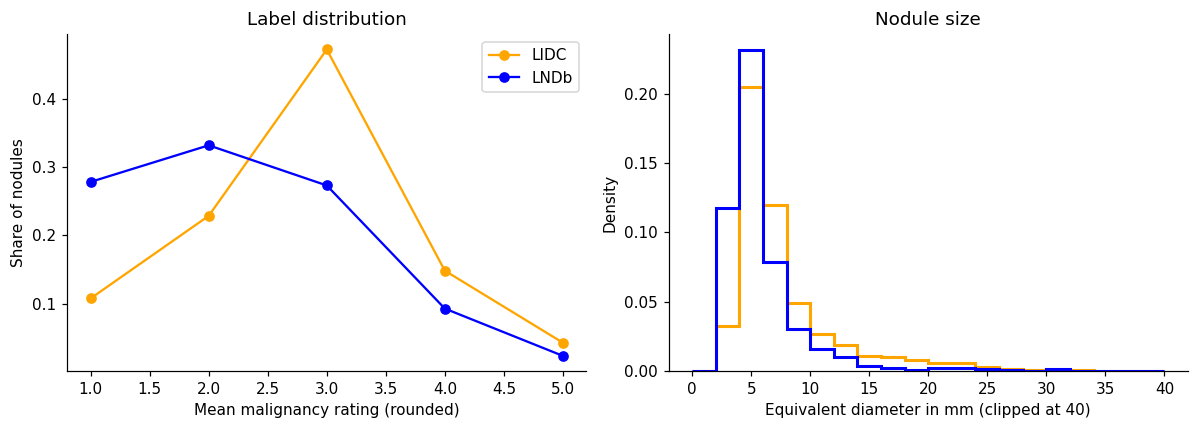

In [30]:
fig, (ax_label, ax_size) = plt.subplots(1, 2, figsize=(11, 4))

for name, group in nodules.groupby("dataset"):
    rounded = np.floor(group["mal_mean"].dropna() + 0.5)     # half up, so 2.5 becomes 3 and not 2
    share = rounded.value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    ax_label.plot(share.index, share.values, marker="o", color=COLORS[name], label=name)

    diameters = group["diameter_mm"].dropna().clip(upper=40)
    ax_size.hist(diameters, bins=np.arange(0, 41, 2), density=True,
                 histtype="step", linewidth=2, color=COLORS[name], label=name)

ax_label.set(xlabel="Mean malignancy rating (rounded)", ylabel="Share of nodules", title="Label distribution")
ax_size.set(xlabel="Equivalent diameter in mm (clipped at 40)", ylabel="Density", title="Nodule size")
ax_label.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The two datasets do not look alike. LNDb leans clearly towards benign ratings, while LIDC peaks at 3. Part of this is a side effect of averaging: LIDC nodules have on average about 2.6 ratings against 1.3 in LNDb, and a mean over several readers who disagree tends to land in the middle. LNDb also contains smaller nodules, which explains its smaller median diameter. Both effects matter when we train on one dataset and test on the other, so we now understand that we should not assume that a rating of 3 means the same thing in both.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Label Views
  </h3>
  <p>
    The model will be trained on 'mal_mean', which keeps the full 1 to 5 scale. For reporting we derive two main views from the same number: a ternary one (benign up to 2.5, indeterminate up to 3.5, malignant above) and a binary one that leaves the indeterminate band empty. Nothing is dropped from the table. If a model wants to ignore the indeterminate nodules it has to say so explicitly with 'label_binary.notna()'.
  </p>
</div>

In [31]:
table["label_ternary"] = pd.cut(table["mal_mean"], bins=[0, 2.5, 3.5, 5],
                                labels=["benign", "indeterminate", "malignant"])
table["label_binary"] = table["label_ternary"].map({"benign": 0, "malignant": 1}).astype(float)

counts = pd.crosstab(table["dataset"], table["label_ternary"], margins=True)
percent = counts.div(counts["All"], axis=0).mul(100).round(0).drop(columns="All").add_suffix(" %")
counts.join(percent)

label_ternary,benign,indeterminate,malignant,All,benign %,indeterminate %,malignant %
dataset,,,,,,,
LIDC,1124,1147,392,2663,42.0,43.0,15.0
LNDb,509,182,74,765,67.0,24.0,10.0
All,1633,1329,466,3428,48.0,39.0,14.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    LIDC has a much bigger indeterminate band than LNDb, which agrees with what the figure showed. This is one more reason to keep these nodules in the table and not to exclude them silently.
  </p>
</div>

In [32]:
if not OUTPUT.exists():                  # never overwrite the table used by the later parts
    table.to_csv(OUTPUT, index=False)
    print(f"Saved {len(table)} rows to {OUTPUT}")
else:
    print(f"{OUTPUT} already exists ({len(pd.read_csv(OUTPUT))} rows); kept as it is")

nodule_table.csv already exists (3882 rows); kept as it is


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits to keep in mind
  </h3>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The datasets do not measure exactly the same thing. LIDC only contains nodules of 3 mm or more, read by up to four radiologists. LNDb also includes smaller nodules and non nodules, and most of its nodules were read by a single radiologist. The label is therefore noisier in LNDb.</li>
    <li style="margin-bottom: 8px;">The regrouped LIDC nodules rest on a heuristic. They are marked in 'reclustered', and a sensitivity analysis with and without them is planned. The few groups that stay above four annotations are kept and flagged in 'oversized_group'. One of them probably mixes several nodules.</li>
    <li style="margin-bottom: 8px;">Coordinates come from each dataset's own frame. They are only meaningful together with their own CT, which is all we need to cut patches.</li>
    <li style="margin-bottom: 8px;">Validation must group by 'patient_id'. Rows from the same patient share scanner and anatomy.</li>
    <li style="margin-bottom: 8px;">Scanners differ a lot. LNDb comes from one hospital and three Siemens models. LIDC mixes many vendors. Any gain from adding LIDC has to be measured on LNDb scans held out by CT.</li>
  </ol>

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    3D Patches Around Every Finding
  </h1>

  <p>
    The model does not see a whole CT scan, only a small cube around each finding. This section explains how the cube is cut, shows that it is cut in the right place, and checks the result on all 1219 training findings and all 2900 test rows of LNDb. We'll use the code from the "3D Patches" section in the beginning of this document.
  </p>

</div>

In [ ]:
pd.set_option("display.width", 140)

# Cut the patches if they are not on disk yet (about 15 minutes for LNDb, 20 for LIDC). Functions: Part 2.1
for split in ("train", "test"):
    if not (PATCHES_DIR / f"manifest_{split}.csv").exists():
        summarise_manifest(cut_lndb_patches(split)[0], split)
if not (PATCHES_DIR / "manifest_lidc.csv").exists():
    cut_lidc_patches()
print("patches on disk:", {s: len(pd.read_csv(PATCHES_DIR / f'manifest_{s}.csv')) for s in ('train', 'test', 'lidc')})

patches on disk: {'train': 1219, 'test': 2900, 'lidc': 2663}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Testing our patches with a known answer
  </h3>
  <p>
    We build artificial scans with a bright blob at a known physical position, with different voxel sizes and tilts, and check that the blob lands on the middle voxel. A test only means something if it can fail, so we also broke the code on purpose in three ways (swapped axes, ignored tilt, a centre shifted by 3 mm) and each break was caught.
  </p>
  </ol>

In [34]:
for test in [test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing, test_axis_order_is_z_y_x, test_tilted_direction_is_handled, test_naive_conversion_would_fail_on_a_tilted_ct, test_points_outside_the_ct_are_filled_with_air_and_counted, test_nearest_neighbour_keeps_integer_labels]:
    test()
    print("passed:", test.__name__)

passed: test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing
passed: test_axis_order_is_z_y_x
passed: test_tilted_direction_is_handled
passed: test_naive_conversion_would_fail_on_a_tilted_ct
passed: test_points_outside_the_ct_are_filled_with_air_and_counted
passed: test_nearest_neighbour_keeps_integer_labels


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Does it work on real scans?
  </h3>
  <p>
    For readings that come with a segmentation mask, the centre we cut around should fall on the centre of the mask. We cut a patch of the mask and measure how far its centre of mass is from the middle voxel. Since voxels are 1 mm, the distance is in millimetres. We used 12 scans: 6 tilted and 6 not tilted. If axes were swapped or the tilt ignored, the distance would be tens of millimetres.
  </p>
</div>

In [35]:
check_patch_coordinates()

45 readings with a mask, from 12 CTs (tilt of the chosen CTs: {'not tilted': {'min': 0.0, 'max': 0.0}, 'tilted': {'min': 3.3, 'max': 6.7}})
readings whose mask is empty inside the patch: 0

distance between the mask centroid and voxel 32 (mm):
            median  90th percentile   max
group                                    
not tilted    0.39             0.62  0.81
tilted        0.41             0.60  0.69
share below 1 mm: 100.0%
share below 2 mm: 100.0%
share below 5 mm: 100.0%

largest distances:
     group  ct  tilt  distance_mm  voxels
not tilted 117   0.0         0.81      23
    tilted 121   3.9         0.69      73
    tilted 121   3.9         0.64      47
not tilted  77   0.0         0.62      34
not tilted  77   0.0         0.62      42


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Every distance is below 1 mm, the same for tilted and untilted scans. What this does not cover: the tilted scans we picked go up to about 7 degrees, while the data reach 13. That extreme is covered by the artificial tests above.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The full run
  </h3>
  <p>
    All findings were cut one scan at a time (to keep memory low). Each finding gets a row in a manifest with its status, where its centre falls inside the scan, and how much of its patch lies outside it.
  </p>
</div>

In [36]:
train = pd.read_csv(PATCHES_DIR / "manifest_train.csv")
test = pd.read_csv(PATCHES_DIR / "manifest_test.csv")
rows = []
for name, m, expected in (("train", train, 1219), ("test", test, 2900)):
    ok = m[m.status == "ok"]
    rows.append({"split": name, "rows": len(m), "expected": expected, "ok": len(ok),
                 "centre outside scan": int((m.status == "centre_outside_volume").sum()),
                 "outside_fraction > 5%": int((ok.outside_fraction > .05).sum()),
                 "outside_fraction > 50%": int((ok.outside_fraction > .5).sum())})
pd.DataFrame(rows).set_index("split")

,rows,expected,ok,centre outside scan,outside_fraction > 5%,outside_fraction > 50%
split,,,,,,
train,1219,1219,1219,0,25,0
test,2900,2900,2895,5,47,1


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The training duplicates
  </h3>
  <p>
    12 training rows share a position with another row in the same CT. We checked what they are. In the LNDb files each finding comes from merging the readings of several radiologists, and readings are merged only if they agree on the type. When one radiologist marked a structure as a nodule and another marked the same place as a non nodule (or as a nodule smaller than 3 mm), the same lesion appears twice.
  </p>
</div>

In [37]:
table = pd.read_csv("nodule_table.csv")
lndb = table[table.dataset == "LNDb"]
from scipy.spatial.distance import cdist
pairs = []
for scan, g in lndb.groupby("scan_id"):
    c = g[["x_mm", "y_mm", "z_mm"]].values
    d = cdist(c, c); np.fill_diagonal(d, 99)
    for i, j in zip(*np.where(np.triu(d < 3))):
        pairs.append((g.mal_mean.notna().iloc[i], g.mal_mean.notna().iloc[j]))
pairs = pd.DataFrame(pairs, columns=["first_has_rating", "second_has_rating"])
print("pairs of rows closer than 3 mm in the same CT:", len(pairs))
print(pairs.value_counts().rename("pairs").to_string())

pairs of rows closer than 3 mm in the same CT: 59
first_has_rating  second_has_rating
True              False                47
False             True                 12


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    In every pair, only one row has a malignancy rating and the other one has none. So the labelled nodules we train on never appear twice, and the duplicates cannot leak the same nodule between the training and validation folds. The unrated twin rows are simply not used for training. Validation is also grouped by CT, so even a hidden duplicate would stay on one side.
  </p>
    <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   A visual check
  </h3>
    <p>
    Twelve random patches, six from training and six from the test file, with the three central views and the centre marked in red. The lung window is used only to display them.
  </p>
</div>

saved /home/anasofia/labiacd/mass_detect/reports/figures/patch_qc.png


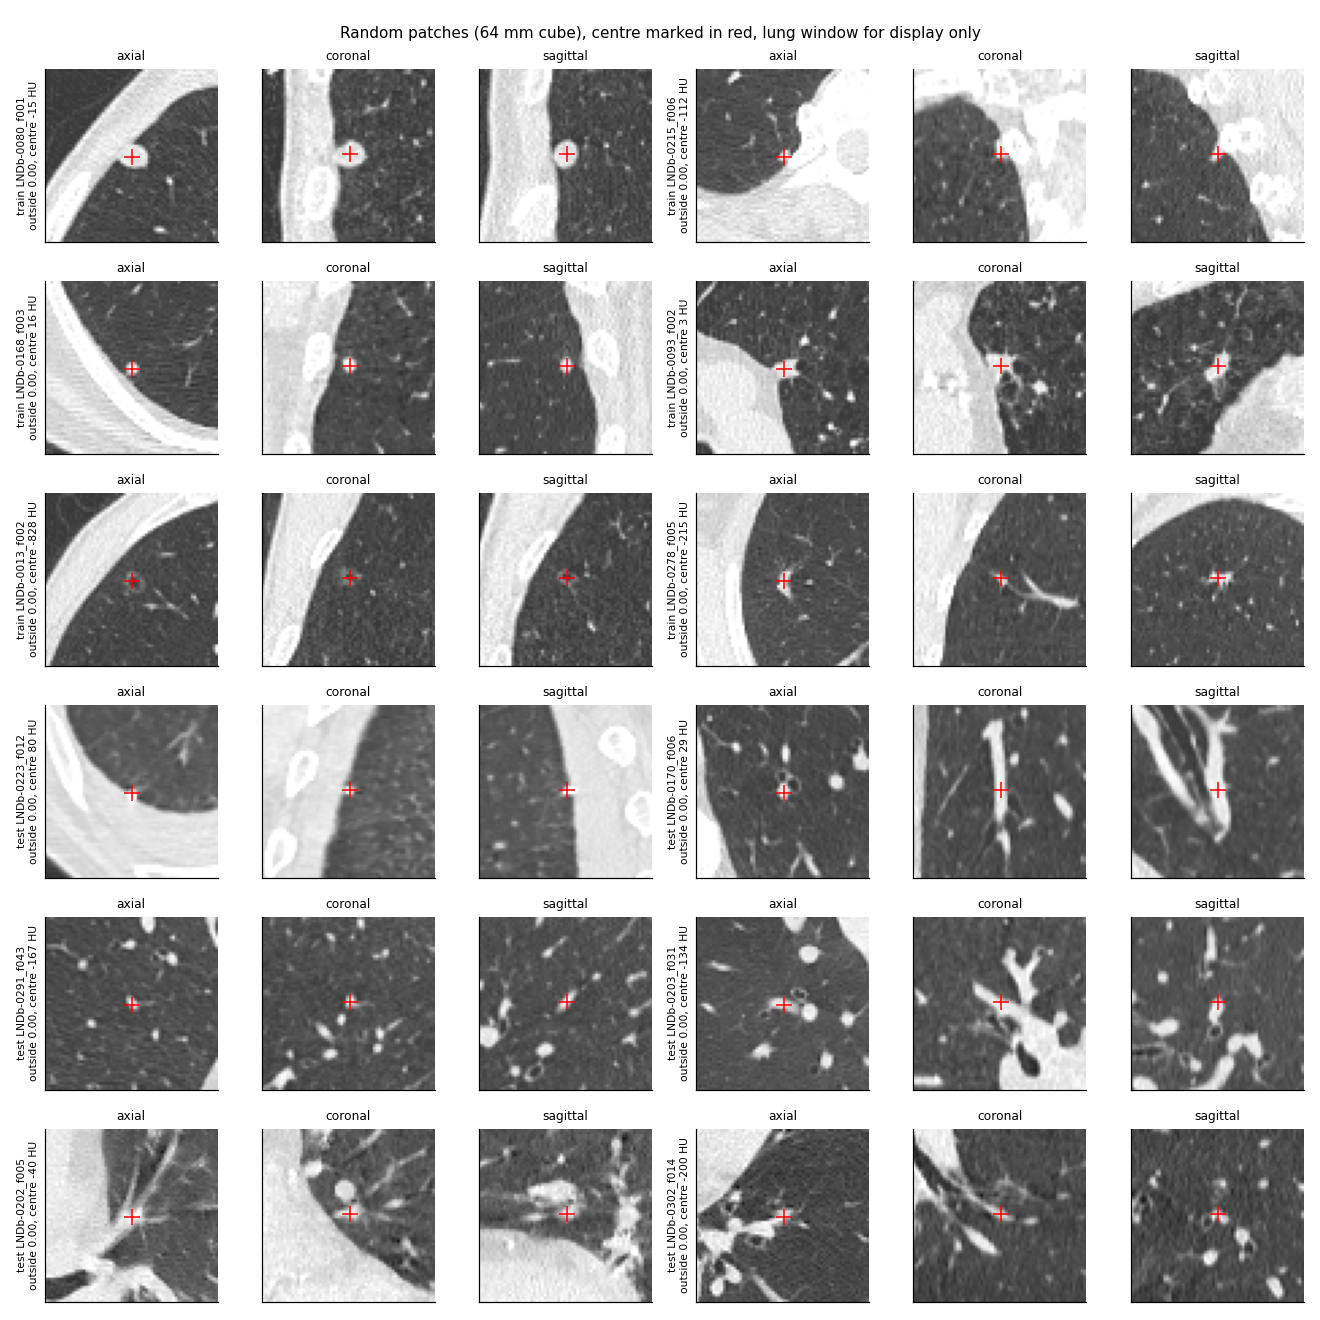

In [38]:
make_patch_qc_figure()
plt.close("all")            # the figure is shown from the saved file below
from IPython.display import Image
Image(filename=str(QC_FIGURE_FILE))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
    <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What the patches already tell us
  </h3>
    <p>
    The tissue at the centre is denser in the test rows than in the training nodules. This fits the idea that the test file contains many structures that are not nodules (vessels, scars)-
  </p>
</div>

In [39]:
def centre_hu(files):
    return np.array([np.load(PATCHES_DIR / f, mmap_mode="r")[31:34, 31:34, 31:34].mean() for f in files])

rated = lndb[lndb.mal_mean.notna()].nodule_uid.str.replace(r"_(\d+)$", lambda m: f"_f{int(m.group(1)):03d}", regex=True)
groups = {"train, rated nodules": train[train.patch_id.isin(rated)].file,
          "train, other findings": train[~train.patch_id.isin(rated)].file,
          "test": test[test.status == "ok"].file}
summary = {}
for name, files in groups.items():
    hu = centre_hu(files)
    summary[name] = {"n": len(hu), "median HU at centre": np.median(hu), "share above -300 HU": (hu > -300).mean()}
pd.DataFrame(summary).T.round(2)

,n,median HU at centre,share above -300 HU
"train, rated nodules",765.0,-242.96,0.57
"train, other findings",454.0,-185.52,0.67
test,2895.0,-103.30,0.81


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
    <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The same patches for LIDC-IDRI
  </h3>
</div>

In [40]:
lidc = pd.read_csv(PATCHES_DIR / "manifest_lidc.csv")
check = lidc.coord_check_mm
print(f"{len(lidc)} LIDC nodules, status: {lidc.status.value_counts().to_dict()}")
print(f"distance between the two computations: median {check.median():.3f} mm, 99th percentile {check.quantile(.99):.3f} mm")
print(f"position verified: {lidc.position_verified.sum()} | not verified: {(~lidc.position_verified).sum()} "
      f"(tilted series without a header point: {check.isna().sum()}, disagreement above 1 mm: {(check > 1).sum()})")

2663 LIDC nodules, status: {'ok': 2663}
distance between the two computations: median 0.000 mm, 99th percentile 0.000 mm
position verified: 2621 | not verified: 42 (tilted series without a header point: 36, disagreement above 1 mm: 6)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
    <p>
    Before using a LIDC patch we make sure it is centred on the right nodule. The centre is computed in two independent ways: Firstly it derives it from the DICOM header of the first slice, and the patch script lets SimpleITK convert the nodule's voxel position into millimetres using the geometry of the scan. If both give the same point, the patch is in the right place. For 2619 nodules the two points agree to less than a micrometre, and for two more within 0.52 mm, less than half a voxel. Six nodules in five series disagree by more than 1 mm, because pylidc and SimpleITK order the slices differently in those series, so the same slice number points to different slices. Another 36 nodules are in tilted series, where the header method does not apply, so their position cannot be confirmed. We leave these 42 nodules (1.6%) out: losing a few examples costs little, while a patch centred on the wrong tissue would teach the size model a wrong measurement. As a visual check, the figure below shows six random verified patches with a red cross at the centre, which should sit on the nodule. 
    </p>
</div>

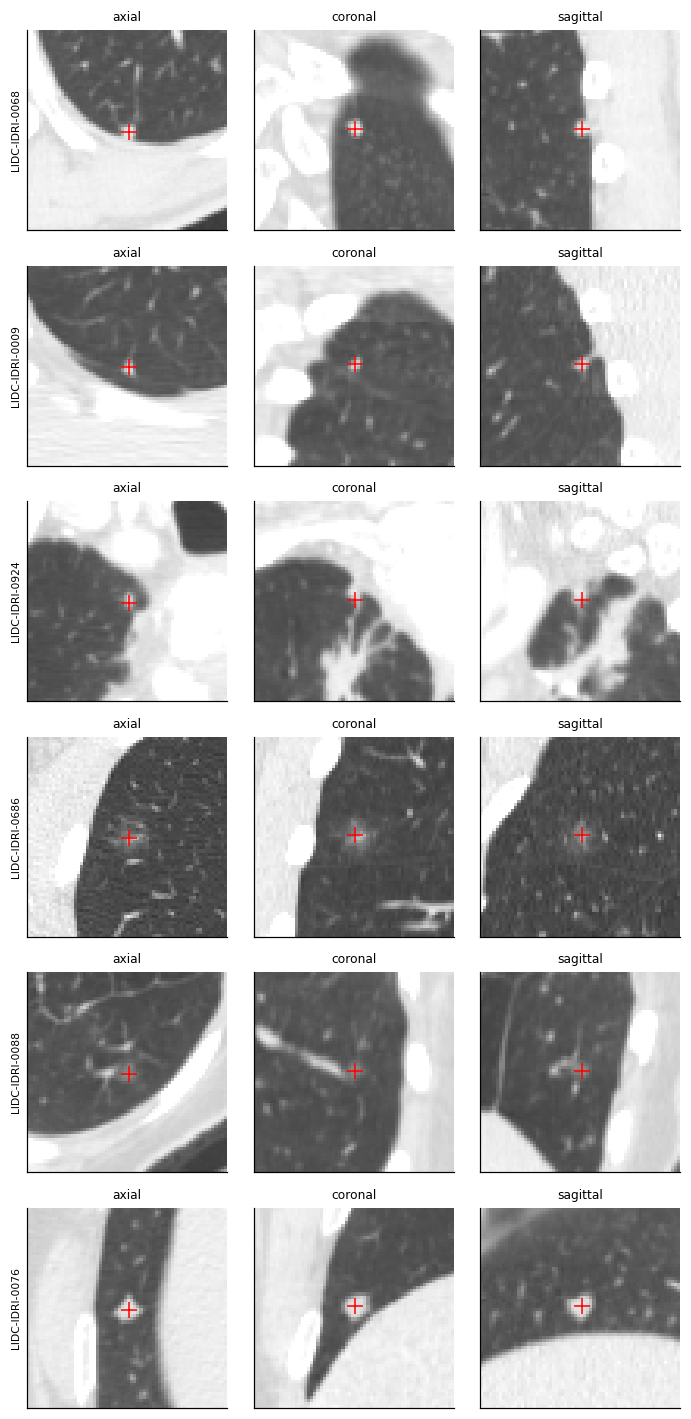

LIDC verified nodules: median HU at the centre -177, share above -300 HU 0.63


In [41]:
rng = np.random.default_rng(0)
picks = lidc[lidc.position_verified].iloc[rng.choice(lidc.position_verified.sum(), 6, replace=False)]
fig, axes = plt.subplots(6, 3, figsize=(6.5, 13))
for row_axes, item in zip(axes, picks.itertuples()):
    patch = np.load(PATCHES_DIR / item.file)
    views = (patch[CENTRE_INDEX], patch[:, CENTRE_INDEX, :], patch[:, :, CENTRE_INDEX])
    for axis, view, name in zip(row_axes, views, ("axial", "coronal", "sagittal")):
        axis.imshow(view, cmap="gray", vmin=-1350, vmax=150, origin="lower" if name != "axial" else "upper")
        axis.plot(CENTRE_INDEX, CENTRE_INDEX, "r+", markersize=10)
        axis.set_xticks([]); axis.set_yticks([]); axis.set_title(name, fontsize=8)
    row_axes[0].set_ylabel(item.patch_id[:14], fontsize=7)
plt.tight_layout(); plt.show()

lidc_hu = centre_hu(lidc[lidc.position_verified].file)
print(f"LIDC verified nodules: median HU at the centre {np.median(lidc_hu):.0f}, share above -300 HU {(lidc_hu > -300).mean():.2f}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The cube is 64 mm, so a nodule bigger than about 40 mm would be cut. In LNDb nodules this large are rare, and the next notebook counts them.</li>
    <li style="margin-bottom: 8px;">25 training and 47 test patches have more than 5% of their voxels outside the scan (near the edge of the volume). They are kept and flagged.</li>
    <li style="margin-bottom: 8px;">42 LIDC nodules (1.6%) whose position could not be confirmed are not used.</li>
  </ul>

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    From Patches to Features
  </h1>

  <p>
Test rows only give us the centre of each finding, nothing else. So everything the model knows about a finding has to be measured from its patch, with the same procedure for training and test. The path is:
  </p>

  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Segment the nodule that sits at the centre of the patch.</li>
    <li style="margin-bottom: 8px;">Measure it (size, shape, density, surroundings), plus statistics in spheres that need no segmentation.</li>
    <li style="margin-bottom: 8px;">Radiomics: PyRadiomics features with an IBSI oriented configuration, and how robust they are when the contour changes.</li>
  </ol>
</div>

In [ ]:
pd.set_option("display.width", 140)

# Measure the patches and extract the radiomic features if this was not done yet. Functions: Part 2.2
if not FEATURES_FILE.exists():
    measure_all_patches()
if not (PATCHES_DIR / "radiomics_train.csv").exists():
    extract_training_radiomics()
print("features:", pd.read_csv(FEATURES_FILE).groupby("split").size().to_dict())

features: {'lidc': 2663, 'test': 2895, 'train': 1219}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Segmenting the nodule from its center
  </h3>
  <p>
  The test file gives only the centre of each finding, so the region of the nodule must be found automatically, and in exactly the same way in training and in test. The method therefore has to be simple, deterministic and robust to the two kinds of nodule we meet: solid ones, about as dense as soft tissue, and ground glass ones, a hazy increase in density through which vessels remain visible Our process works in 5 steps.
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Light smoothing (Gaussian, sigma 0.7 mm). CT images contain noise, so a few voxels inside a nodule fall below any threshold and a few voxels of lung rise above it. Thresholding a noisy image gives a ragged mask with holes and isolated specks. A light Gaussian filter is the standard remedy before thresholding (Gonzalez and Woods, 2018). We keep sigma below one voxel (0.7 mm) so that the edges of nodules of 3 to 5 mm are not blurred away.</li>
    <li style="margin-bottom: 8px;">An adaptive threshold halfway between the nodule and the lung. We measure the density of the centre (median within 2 mm) and of the surrounding lung (median of the voxels below −500 HU in a shell 24 to 31 mm from the centre; −850 HU if there are too few), and threshold halfway between the two, never above −300 HU. Because of the partial volume effect, voxels on the border of a nodule mix nodule and lung, so the true edge lies where the intensity is halfway between object and background, the same idea as the full width at half maximum. A fixed threshold cannot serve both kinds of nodule: −400 HU captures a solid nodule (centre about 0 HU, threshold −425 HU with ours) but misses a ground glass one entirely (centre about −500 HU, threshold −675 HU with ours). The cap at −300 HU protects calcified nodules: with a centre at +400 HU a halfway threshold would cut away their softer parts. If the centre is not at least 150 HU denser than the lung, there is no nodule-like structure and the mask is left empty.</li>
    <li style="margin-bottom: 8px;">Keep the region connected to the centre. Many structures in the patch exceed the threshold: other vessels, ribs, the heart. Only the object the finding points at matters, so we keep the connected component that touches the centre (connected component labelling; Gonzalez and Woods, 2018), within 28 mm of it.</li>
    <li style="margin-bottom: 8px;">Cut the attachments to vessels and pleura. Vessels and the chest wall are as dense as the nodule and often touch it, so the region of step 3 may include a long piece of vessel or a slice of pleura, and its volume would be far too large. Separating a nodule from attached structures is the main difficulty of nodule segmentation. Published methods use morphological opening (Kostis et al., 2003) or combine region growing, morphology and a partial volume analysis (Kuhnigk et al., 2006). We use a simpler geometric rule. The Euclidean distance transform gives, for every voxel of the region, its distance to the region's border (Danielsson, 1980). The deepest voxel near the centre (within 1.5 mm) is the centre of the largest sphere that fits inside the region, and its distance is that sphere's radius r. A vessel is a thin tube, so the spheres that fit inside it are small; the largest one sits in the nodule, which is the thickest part. We then remove every voxel farther than 1.2 × r + 1 mm from that point. The 20% margin and the extra millimetre keep the irregular border of the nodule (lobulation, short spicules), while vessels leaving the nodule and the pleural surface are cut off.</li>
    <li style="margin-bottom: 8px;">Keep the region connected to the centre again. The cut of step 4 can leave loose pieces, for example the end of a vessel that lies within the radius but no longer touches the nodule. We keep only the component that contains the centre of the inscribed sphere.</li>
  </ol>

<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Checking against the radiologists' masks
  </h3>
    <p>
    LNDb has a hand drawn mask for most nodules of 3 mm or more. For a random sample of 250 of them, we compare our mask with each radiologist's mask using the Dice coefficient (1 means identical, 0 means no overlap), and our equivalent diameter with theirs. As a reference for how hard this is, we also measure the Dice between two radiologists on the same nodule.
    </p>
</div>

In [43]:
table = pd.read_csv("nodule_table.csv")
lndb = table[table.dataset == "LNDb"].copy()
gt = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
gt["nodule_uid"] = gt.apply(lambda r: f"LNDb-{r.LNDbID:04d}_{r.FindingID}", axis=1)
has_mask = lndb[lndb.mal_mean.notna() & ~lndb.volume_is_placeholder]
gt = gt.merge(has_mask[["nodule_uid"]], on="nodule_uid")
sample = gt.iloc[np.random.default_rng(1).choice(len(gt), size=250, replace=False)].sort_values("LNDbID")

def diameter(voxels):
    return 2 * (3 * voxels / (4 * np.pi)) ** (1 / 3)

records = []
for r in sample.itertuples():
    patch = np.load(PATCHES_DIR / f"train/LNDb-{r.LNDbID:04d}_f{r.FindingID:03d}.npy")
    references = []
    for rad, finding in zip(str(r.RadID).split(","), str(r.RadFindingID).split(",")):
        mask_file = LNDB_DIR / "LNDb_masks" / "masks" / f"LNDb-{r.LNDbID:04d}_rad{rad}.mhd"
        mask_patch, _ = extract_patch(sitk.ReadImage(str(mask_file)), (r.x, r.y, r.z),
                                      interpolator=sitk.sitkNearestNeighbor, outside_value=0)
        references.append(mask_patch == int(finding))
    mask, _ = segment_from_centre(patch)
    dice = lambda a, b: 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)
    records.append({"uid": r.nodule_uid, "patch": patch, "mask": mask, "refs": references,
                    "dice": np.mean([dice(mask, q) for q in references]),
                    "diameter": diameter(mask.sum()), "ref_diameter": diameter(np.mean([q.sum() for q in references])),
                    "reader_dice": dice(references[0], references[1]) if len(references) > 1 else np.nan})
check = pd.DataFrame(records)
half = len(check) // 2
rows = {}
for name, part in (("first half (used to pick parameters)", check.iloc[:half]), ("second half (not used)", check.iloc[half:]), ("all 250", check)):
    rows[name] = {"median Dice": part.dice.median(), "mean Dice": part.dice.mean(),
                  "diameter correlation": part.diameter.corr(part.ref_diameter),
                  "mean abs diameter error (mm)": (part.diameter - part.ref_diameter).abs().mean(),
                  "mean diameter bias (mm)": (part.diameter - part.ref_diameter).mean()}
print(pd.DataFrame(rows).T.round(2).to_string())
print(f"\nDice between two radiologists on the same nodule: median {check.reader_dice.median():.2f}, mean {check.reader_dice.mean():.2f} (n={check.reader_dice.notna().sum()})")
print(f"nodules the pipeline could not segment: {(check['mask'].apply(lambda m: m.sum()) == 0).sum()} of 250")

                                      median Dice  mean Dice  diameter correlation  mean abs diameter error (mm)  mean diameter bias (mm)
first half (used to pick parameters)         0.64       0.60                  0.74                          1.38                    -0.01
second half (not used)                       0.59       0.55                  0.67                          1.56                    -0.20
all 250                                      0.64       0.57                  0.72                          1.47                    -0.10

Dice between two radiologists on the same nodule: median 0.74, mean 0.68 (n=90)
nodules the pipeline could not segment: 13 of 250


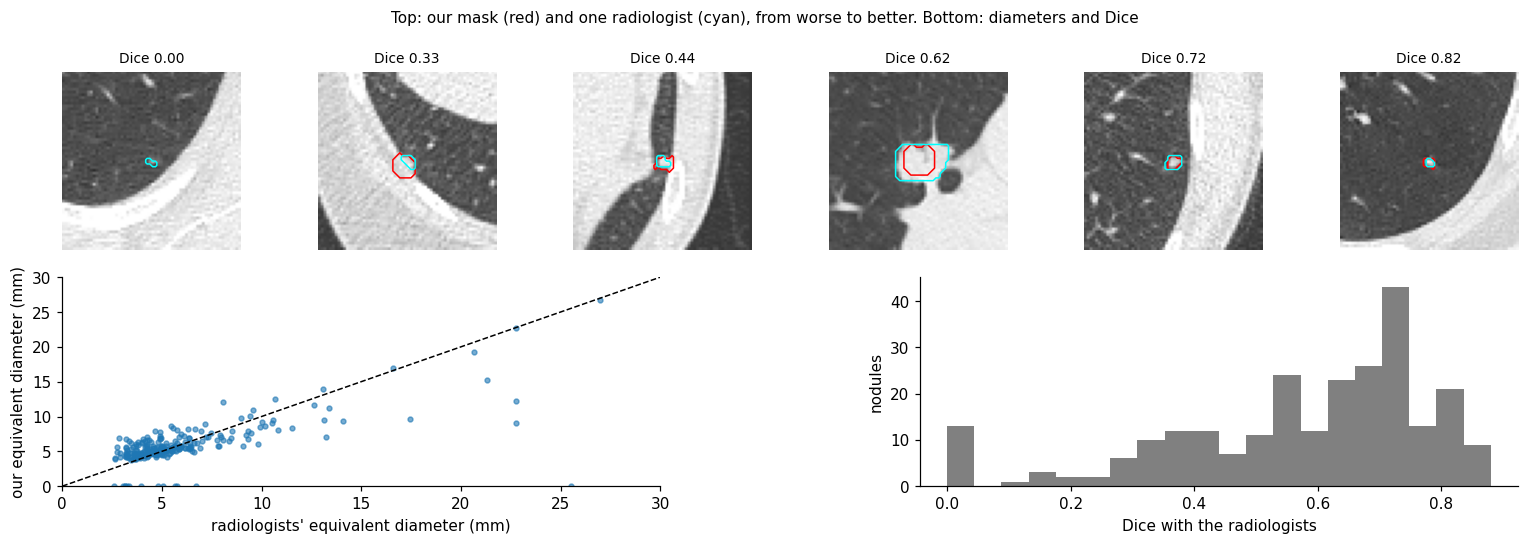

In [44]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
order = check.sort_values("dice")
picks = list(order.iloc[[10, 30, 60]].index) + list(order.iloc[[120, 180, 235]].index)
for axis, i in zip(axes[0], picks):
    p, m, q = check.patch[i], check["mask"][i], check.refs[i][0]
    axis.imshow(p[32], cmap="gray", vmin=-1350, vmax=150)
    axis.contour(m[32], levels=[.5], colors="red", linewidths=1)
    axis.contour(q[32], levels=[.5], colors="cyan", linewidths=1)
    axis.set_title(f"Dice {check.dice[i]:.2f}", fontsize=9); axis.axis("off")
axes[0, 0].set_ylabel("axial")
a = axes[1, 0]; a.remove()
ax = fig.add_subplot(2, 2, 3)
ax.scatter(check.ref_diameter, check.diameter, s=10, alpha=.6); ax.plot([0, 30], [0, 30], "k--", lw=1)
ax.set_xlabel("radiologists' equivalent diameter (mm)"); ax.set_ylabel("our equivalent diameter (mm)"); ax.set_xlim(0, 30); ax.set_ylim(0, 30)
for a in axes[1, 1:]: a.remove()
ax2 = fig.add_subplot(2, 2, 4)
ax2.hist(check.dice, bins=20, color="grey"); ax2.set_xlabel("Dice with the radiologists"); ax2.set_ylabel("nodules")
fig.suptitle("Top: our mask (red) and one radiologist (cyan), from worse to better. Bottom: diameters and Dice", fontsize=10)
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
The two radiologists agree with each other much better than we agree with them, so our segmentation is not at their level. It is good enough to measure size on average (small bias, error around 1.5 mm) and fails mostly on nodules attached to vessels or the chest wall. We keep it because it uses nothing but the centre, so it can be applied to the test rows. A better segmentation is the most direct way to improve the features later.
</p>
<p>
One more check: the cube is 64 mm. Does any rated nodule risk being cut?
</p>
</div>

In [45]:
rated = lndb[lndb.mal_mean.notna()]
print("rated LNDb nodules:", len(rated))
print("with a radiologist diameter above 40 mm:", int((rated.diameter_mm > 40).sum()), "| above 30 mm:", int((rated.diameter_mm > 30).sum()))

rated LNDb nodules: 765
with a radiologist diameter above 40 mm: 0 | above 30 mm: 2


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    What we measure
  </h3>
<p>
For every patch we compute 21 numbers on the segmented nodule and 9 numbers in spheres around the centre. We wrote them ourselves instead of starting from the hundreds of PyRadiomics features, for three reasons: with 765 labelled nodules, hundreds of features invite overfitting; each of ours has a plain meaning that we can explain; and they are fast. Section 4 checks whether PyRadiomics adds anything.
</p>

| Group | Features | Why |
|---|---|---|
| Size | 'volume_mm3', 'diameter_mm' (of the sphere with the same volume), 'max_extent_mm' | Size is the first thing a radiologist looks at, and a diameter only baseline is strong in LIDC (Baltatzis et al., 2021) |
| Shape | 'elongation', 'flatness', 'sphericity' | Round and smooth nodules look different from spiculated or elongated ones |
| Density inside | 'hu_mean', 'hu_std', 'hu_p10', 'hu_p50', 'hu_p90', 'hu_skew' | Calcified nodules are very dense and are usually benign |
| Solid or ground glass | 'solid_fraction', 'ground_glass_fraction' | Part solid and ground glass nodules are read differently from solid ones |
| Edge | 'edge_gradient' | How sharp the border is |
| Surroundings | 'ring_mean_hu', 'ring_solid_fraction', 'contrast_hu' | A dense ring means the nodule touches a vessel or the wall |
| Segmentation | 'centre_hu', 'lung_hu', 'threshold_hu' | What the segmentation measured, which also says how confident it is |
| Spheres of 3, 5 and 8 mm | mean HU, 90th percentile, solid fraction | They need no mask, so they exist even when the segmentation fails (8% of the rated nodules), in training and test alike |

<p>
Two safeguards: every intensity feature uses the patch clipped to [-1024, 3071] HU, the range of a 12 bit CT, because some patches contain padding values down to -8192 or artefacts up to 22544 HU (the IBSI calls this re-segmentation by intensity range; Zwanenburg et al., 2020). And nodules where nothing denser than the lung is found at the centre get empty segmentation features; the model fills them with the median, but their sphere features remain.
</p>
</div>

765 rated nodules; segmented: 91.9% | features: 30
test rows with features: 2895 | segmented: 98.5%
rating
1    213
2    254
3    209
4     71
5     18


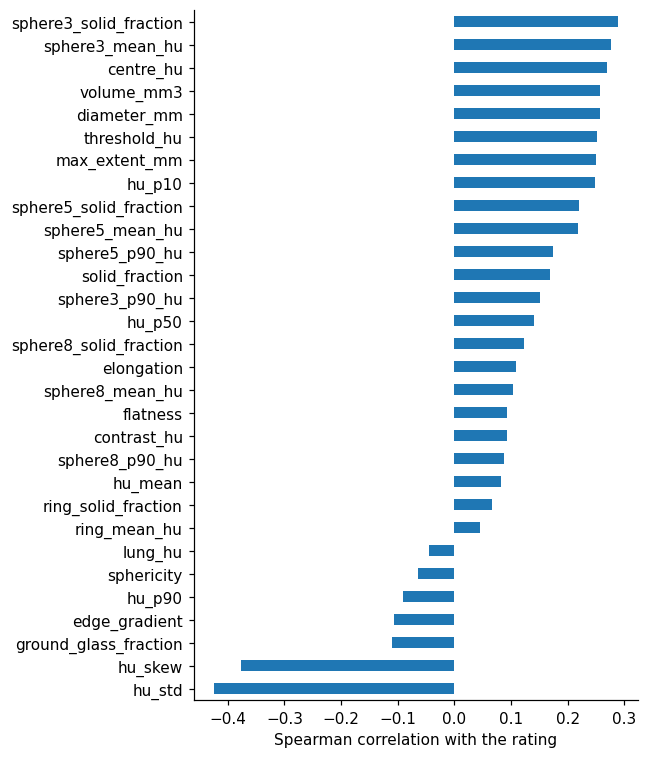

In [46]:
features = pd.read_csv(PATCHES_DIR / "features.csv")
lndb["patch_id"] = lndb.nodule_uid.str.replace(r"_(\d+)$", lambda m: f"_f{int(m.group(1)):03d}", regex=True)
data = (lndb[lndb.mal_mean.notna()].rename(columns={"diameter_mm": "diameter_mm_radiologist"}).drop(columns="volume_mm3")
        .merge(features[features.split == "train"].drop(columns="split"), on="patch_id"))
data["rating"] = np.floor(data.mal_mean + 0.5).astype(int)          # mean of the readers, rounded half up
feature_names = [c for c in features.columns if c not in ("patch_id", "split", "segmented", "error")]
print(len(data), "rated nodules; segmented:", f"{data.segmented.mean():.1%}", "| features:", len(feature_names))
print("test rows with features:", int((features.split == "test").sum()), "| segmented:", f"{features[features.split == 'test'].segmented.mean():.1%}")
print(data.rating.value_counts().sort_index().rename("nodules per class").to_string())

corr = data[feature_names + ["rating"]].corr(method="spearman")["rating"].drop("rating").sort_values()
corr.plot.barh(figsize=(6, 7)); plt.xlabel("Spearman correlation with the rating"); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
    The strongest single signals are the density inside the nodule and in the small spheres (calcified nodules are dense and benign, so the sign is negative), the surroundings and the size. We know understand that no single feature is strong, so the combination matters.
</p>

| Step | Our choice | Why |
|---|---|---|
| Resampling | 1 mm isotropic, linear interpolation, done when the patch is cut | Texture depends on voxel size (Shafiq-ul-Hassan et al., 2017); the IBSI recommends isotropic voxels |
| Intensity range | [-1024, 3071] HU | Removes padding and artefacts before discretisation |
| Discretisation | fixed bin width of 25 HU | For calibrated units such as HU the IBSI recommends a fixed bin size, so that one bin is the same density in every scan |
| Filters | original image and Laplacian of Gaussian with sigma 1, 2 and 3 mm | Edges and blobs at the scale of small nodules |
| Feature classes | first order, shape, GLCM, GLRLM, GLSZM, GLDM, NGTDM | All classes of PyRadiomics, 386 features |
| Region | the automatic mask, identical in training and test | The test file only has centres (Pedrosa et al., 2019) |

</div>

In [47]:
print("settings:", SETTINGS, "| LoG sigmas (mm):", LOG_SIGMAS_MM)
radiomics = pd.read_csv(PATCHES_DIR / "radiomics_train.csv")
icc = pd.read_csv(PATCHES_DIR / "radiomics_icc.csv")
print("regions:", radiomics.roi.value_counts().to_dict())

settings: {'binWidth': 25, 'resampledPixelSpacing': None, 'interpolator': 'sitkLinear', 'label': 1, 'minimumROIDimensions': 1, 'minimumROISize': 8, 'geometryTolerance': 0.001} | LoG sigmas (mm): [1.0, 2.0, 3.0]
regions: {'auto': 765, 'rad1': 518, 'rad2': 393, 'rad3': 119}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Are the features robust to who draws the contour?
  </h3>
<p>
A feature that changes a lot when another radiologist draws the contour measures the contour more than the nodule (Traverso et al., 2018; Zwanenburg et al., 2019). For every nodule with masks from two radiologists we compute, feature by feature, the intraclass correlation ICC(2,1): two way random effects, absolute agreement, single rater (Shrout and Fleiss, 1979). Following Koo and Li (2016), ICC of 0.75 or more is "good" and we call the feature robust.
</p>
</div>

In [48]:
summary = icc.groupby(["image", "feature_class"]).agg(features=("icc", "size"), median_icc=("icc", "median"),
                                                      robust_share=("robust", "mean")).round(2)
print(f"{icc.robust.sum()} of {len(icc)} features are robust (ICC >= 0.75); median ICC {icc.icc.median():.2f}")
summary.unstack("image")["robust_share"]

330 of 386 features are robust (ICC >= 0.75); median ICC 0.94


image,log-sigma-1-0-mm-3D,log-sigma-2-0-mm-3D,log-sigma-3-0-mm-3D,original
feature_class,,,,
firstorder,0.83,0.89,0.94,0.67
glcm,0.88,0.92,0.96,0.75
gldm,0.86,0.93,0.93,0.79
glrlm,0.88,1.00,1.00,0.75
glszm,0.94,0.81,0.75,0.81
ngtdm,0.60,0.80,0.60,0.80
shape,NaN,NaN,NaN,0.86


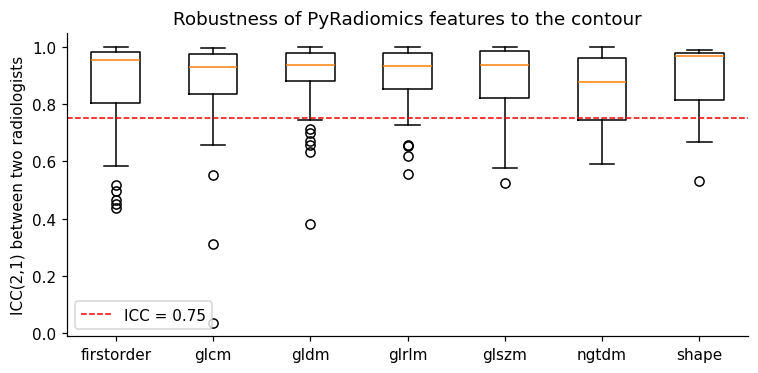

In [49]:
fig, ax = plt.subplots(figsize=(7, 3.5))
classes = sorted(icc.feature_class.unique())
ax.boxplot([icc.loc[icc.feature_class == c, "icc"].clip(lower=-0.2) for c in classes], tick_labels=classes)
ax.axhline(0.75, color="red", linestyle="--", linewidth=1, label="ICC = 0.75")
ax.set(ylabel="ICC(2,1) between two radiologists", title="Robustness of PyRadiomics features to the contour")
ax.legend(); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
Most features are robust to the difference between two radiologists' contours; NGTDM and the unfiltered texture features are the least robust. But the region we can use at test time is our automatic mask, not a radiologist's. The relevant question is therefore how well features from our mask agree with features from a radiologist's mask.
</p>
</div>

In [50]:
first_reader = (radiomics[radiomics.roi.str.startswith("rad")].dropna(subset=["original_firstorder_Mean"])
                .sort_values("roi").groupby("patch_id").head(1).set_index("patch_id"))
automatic = radiomics[radiomics.roi == "auto"].dropna(subset=["original_firstorder_Mean"]).set_index("patch_id")
common = automatic.index.intersection(first_reader.index)
icc_auto = pd.Series({f: icc_2_1(np.column_stack([automatic.loc[common, f], first_reader.loc[common, f]]))
                      for f in icc.feature})
print(f"automatic mask vs radiologist ({len(common)} nodules): median ICC {icc_auto.median():.2f}, "
      f"robust {(icc_auto >= 0.75).mean():.0%} of the features")

automatic mask vs radiologist (632 nodules): median ICC 0.73, robust 47% of the features


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Between two radiologists the median ICC is about 0.94; between our mask and a radiologist it drops to about 0.73, with fewer than half of the features robust. The weak point is our segmentation, not the features.
  </p>

<h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Model, Validation, Submission
  </h1>
  
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Do radiomics add anything to our features?
  </h3>
<p>
We compare, with the ordinal model and the same grouped cross validation, our 30 features alone against our features plus the robust radiomic features. With 300 extra features we remove redundant ones (absolute Spearman correlation above 0.9) and keep the 30 most related to the rating, both inside each training fold  and use a stronger penalty.
</p>
</div>

In [ ]:
robust = ["R_" + f for f in icc.loc[icc.robust, "feature"]]
data = data.merge(automatic[icc.feature].add_prefix("R_"), left_on="patch_id", right_index=True, how="left")
own = feature_names                     # our 21 + 9 sphere features
y, groups = data.rating.to_numpy(), data.scan_id.to_numpy()

def ordinal_pipeline(selection=(), alpha=1.0):
    return lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), *[s() for s in selection],
                                 OrdinalLogisticRegression(alpha))
comparison = {
    "our 30 features": summarise(y, groups, grouped_cv_predictions(ordinal_pipeline(), data[own], y, groups, repeats=3))["mean"],
    "our features + robust radiomics": summarise(y, groups, grouped_cv_predictions(
        ordinal_pipeline((lambda: CorrelationFilter(0.9), lambda: SelectKBest(f_regression, k=30)), alpha=10.0),
        data[own + robust], y, groups, repeats=3))["mean"]}
pd.DataFrame(comparison).T

,balanced_accuracy,macro_f1,qwk,mae,composite
our 30 features,0.377,0.406,0.501,0.633,0.651
our features + robust radiomics,0.355,0.379,0.470,0.644,0.561


In [52]:
# The same question for the size model of notebook 05: does it predict the radiologists' diameter better with radiomics?
target = size_target(data.diameter_mm_radiologist).to_numpy()
measured = data.diameter_mm_radiologist.notna().to_numpy()
for name, columns in (("our features", own), ("our features + robust radiomics", own + robust)):
    predicted = np.zeros(len(data))
    for train, test in GroupKFold(5).split(data, y, groups):
        predicted[test] = make_size_model().fit(data[columns].iloc[train], target[train]).predict(data[columns].iloc[test])
    rho = pd.Series(predicted[measured]).corr(data.diameter_mm_radiologist[measured].reset_index(drop=True), method="spearman")
    print(f"size model with {name}: Spearman {rho:.3f}")

size model with our features: Spearman 0.828
size model with our features + robust radiomics: Spearman 0.822


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The robust radiomic features do not improve the model, neither as direct inputs nor through the size model, so the final model uses our 30 features. This follows the principle of keeping the simplest model that performs as well, and it agrees with the Radiomics Quality Score, which rewards feature reduction and robustness analysis rather than the number of features (Lambin et al., 2017). The radiomic analysis stays in the report as evidence. We consider that A better segmentation would be the way to make radiomics worthwhile.
  </p>

<h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Model, Validation, Submission
  </h1>
  
</div>

In [ ]:
pd.set_option("display.width", 160)
REPEATS = 3          # 3 x 5 folds per model: enough to rank models, and this part runs in about 20 minutes

# Individual LIDC ratings for the agreement ceiling (needs pylidc; Part 2.4), if not on disk yet
if not READER_RATINGS_FILE.exists():
    save_lidc_reader_ratings()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The data
  </h3>
  <p>
  One row per nodule with a malignancy rating, from LNDb and LIDC-IDRI with the features of its patch.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Only nodules are used - non nodules have no rating and would only add noise. LNDb nodules smaller than 3 mm are nodules with a rating, so they stay. </li>
    <li style="margin-bottom: 8px;">The label is the mean of the radiologists' ratings rounded half up (2.5 becomes 3). </li>
    <li style="margin-bottom: 8px;">LIDC rows are kept only when the position of the nodule was confirmed by two independent computations as previously stated.</li>
    <li style="margin-bottom: 8px;">'size_target' is the log of the radiologists' equivalent diameter (2.5 mm for nodules under 3 mm, which have no segmentation). It is only used as a training target.</li>
    <li style="margin-bottom: 8px;">'group' is the patient, so that all nodules of a CT stay on the same side of every split.</p>
  </ul>
</div>

In [54]:
def lndb_patch_id(nodule_uid):
    ct, finding = nodule_uid.rsplit("_", 1)
    return f"{ct}_f{int(finding):03d}"

table = pd.read_csv("nodule_table.csv")
features = pd.read_csv(PATCHES_DIR / "features.csv")
lidc_manifest = pd.read_csv(PATCHES_DIR / "manifest_lidc.csv")

nodules = table[(table.is_nodule == 1) & table.mal_mean.notna()].copy()
nodules["patch_id"] = [lndb_patch_id(u) if d == "LNDb" else u for u, d in zip(nodules.nodule_uid, nodules.dataset)]
nodules = nodules.rename(columns={"diameter_mm": "radiologist_diameter_mm"}).drop(columns="volume_mm3")
data = nodules.merge(features.drop(columns="split"), on="patch_id")
verified = lidc_manifest.loc[lidc_manifest.position_verified, "patch_id"]
data = data[(data.dataset == "LNDb") | data.patch_id.isin(verified)].reset_index(drop=True)

data["rating"] = np.floor(data.mal_mean + 0.5).astype(int)
data["size_target"] = size_target(data.radiologist_diameter_mm)
data["group"] = data.patient_id
data["batch"] = batch_of(data.dataset.values, data.manufacturer.values)
data["is_lidc"] = (data.dataset == "LIDC").astype(int)

HANDCRAFTED = ["centre_hu", "lung_hu", "threshold_hu", "volume_mm3", "diameter_mm", "max_extent_mm", "elongation",
               "flatness", "sphericity", "hu_mean", "hu_std", "hu_p10", "hu_p50", "hu_p90", "hu_skew", "solid_fraction",
               "ground_glass_fraction", "edge_gradient", "ring_mean_hu", "ring_solid_fraction", "contrast_hu"]
SPHERE = [c for c in features.columns if c.startswith("sphere")]
FEATURES = HANDCRAFTED + SPHERE

is_lndb = (data.dataset == "LNDb").to_numpy()
lndb = data[is_lndb].reset_index(drop=True)
y, groups = lndb.rating.to_numpy(), lndb.group.to_numpy()
print(data.groupby("dataset").size().to_dict(), "| features:", len(FEATURES))
print("LNDb classes:", lndb.rating.value_counts().sort_index().to_dict())

{'LIDC': 2621, 'LNDb': 765} | features: 30
LNDb classes: {1: 213, 2: 254, 3: 209, 4: 71, 5: 18}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Validation and measurements
  </h3>
  <p>
  The competition metrics are: Balanced accuracy, macro F1, QWK and MAE. They pull in different directions: balanced accuracy and macro F1 give each class the same weight, so they reward getting the rare classes 4 and 5 right; QWK and MAE reward being close, which favours predictions near the centre.
  </p>
  <p>
  We'll consider extra metrics for our own decisions:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">'composite = BA + F1 + QWK - MAE'. The ranking is the mean rank over the four metrics. </li>
    <li style="margin-bottom: 8px;">'within_one' (share of predictions at most one class away) and 'sensitivity_4_5' (share of nodules rated 4 or 5 that are predicted 4 or 5), which are easier to read clinically.</li>
  </ul>
  <p>
  Regarding the design... Folds grouped by patient and stratified by class (StratifiedGroupKFold), repeated with different seeds, because with 765 nodules one split has wide error bars (Varoquaux, 2018). Intervals come from resampling whole CTs (cluster bootstrap, Field and Welsh, 2007). When LIDC is used it is always on the training side; only LNDb nodules are ever validated, because the test set is LNDb.
  </p>
  <p>
  A model trained on radiologists' ratings cannot be expected to agree with them better than they agree with each other. We measure the agreement between two radiologists on the same nodule, for LNDb and for LIDC. 
  </p>
</div>

In [55]:
def pairwise_agreement(ratings_by_nodule):
    # every pair of radiologists that rated the same nodule
    first, second = [], []
    for ratings in ratings_by_nodule:
        for i in range(len(ratings)):
            for j in range(i + 1, len(ratings)):
                first.append(ratings[i]); second.append(ratings[j])
    return pd.Series(competition_metrics(np.array(first), np.array(second))).round(3), len(first)

# LNDb: readings (trainNodules.csv) and their malignancy (chars_trainNodules.csv) are in the same row order (notebook 02)
readings = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules.csv")
readings["malignancy"] = pd.read_csv(LNDB_DIR / "data" / "chars_trainNodules.csv")["malignancy"].values
merged = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
lookup = readings.set_index(["LNDbID", "RadID", "FindingID"])["malignancy"]
lndb_ratings = []
for row in merged[merged.RadID.astype(str).str.contains(",")].itertuples():
    values = [lookup[(row.LNDbID, int(r), int(f))] for r, f in zip(str(row.RadID).split(","), str(row.RadFindingID).split(","))]
    values = [int(v) for v in values if v > 0]            # 0 means "not filled in"
    if len(values) >= 2:
        lndb_ratings.append(values)

lidc_ratings = pd.read_csv(PATCHES_DIR / "lidc_reader_ratings.csv").groupby("nodule").malignancy.apply(list)
lidc_ratings = [r for r in lidc_ratings if len(r) >= 2]

ceiling = {}
for name, ratings in (("LNDb", lndb_ratings), ("LIDC", lidc_ratings)):
    scores, n_pairs = pairwise_agreement(ratings)
    ceiling[f"{name}: radiologist vs radiologist ({n_pairs} pairs)"] = scores
pd.DataFrame(ceiling).T

,balanced_accuracy,macro_f1,qwk,mae
LNDb: radiologist vs radiologist (309 pairs),0.445,0.411,0.527,0.790
LIDC: radiologist vs radiologist (7313 pairs),0.384,0.390,0.466,0.884


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Two radiologists of the same hospital agree with QWK of about 0.53 and differ by almost 0.8 classes on average; in LIDC the agreement is lower. This is the noise level of our labels and the reason why no model will get close to perfect scores. 
  </p>
</div>

In [56]:
results, oof = {}, {}

def evaluate(name, make_model, use_lidc=False, repeats=REPEATS, first_seed=0):
    # LNDb only, or LNDb + LIDC with LIDC always in training. Only LNDb nodules are validated.
    if use_lidc:
        predictions = grouped_cv_predictions(make_model, data, data.rating.to_numpy(), data.group.to_numpy(),
                                             repeats, evaluate_mask=is_lndb, first_seed=first_seed)
        predictions = [p[is_lndb] for p in predictions]
    else:
        predictions = grouped_cv_predictions(make_model, lndb, y, groups, repeats, first_seed=first_seed)
    oof[name] = predictions
    results[name] = summarise(y, groups, predictions)["mean"]
    return results[name]

oof["constant 2"] = [np.full(len(y), 2)]
results["constant 2"] = summarise(y, groups, oof["constant 2"])["mean"]
evaluate("v1: ridge + tuned cuts", lambda: RidgeWithTunedCuts(HANDCRAFTED))
evaluate("ordinal", lambda: NoduleMalignancyModel(HANDCRAFTED))
evaluate("ordinal + size", lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES))
pd.DataFrame(results).T

,balanced_accuracy,macro_f1,qwk,mae,composite
constant 2,0.200,0.100,0.000,0.808,-0.508
v1: ridge + tuned cuts,0.409,0.395,0.513,0.716,0.601
ordinal,0.378,0.410,0.510,0.627,0.671
ordinal + size,0.375,0.403,0.518,0.619,0.678


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The ordinal model lowers the MAE by about 0.09 class compared with v1 at the same QWK, because it keeps predictions close to where the probability mass is, while the tuned cut points of v1 push predictions outwards to win balanced accuracy. It loses some balanced accuracy, which section 5 recovers. Adding the learned size raises QWK and lowers MAE a little.
  </p>
  <p>
  How good is the learned size? On LNDb nodules with a segmentation, the Spearman correlation with the radiologists' diameter is shown below for our automatic segmentation and for the size model (out of fold, grouped by CT).
  </p>
</div>

In [ ]:
def size_quality(extra_rows=None):
    predicted = np.zeros(len(lndb))
    for train, test in GroupKFold(5).split(lndb, y, groups):
        rows = lndb.iloc[train] if extra_rows is None else pd.concat([lndb.iloc[train], extra_rows])
        predicted[test] = make_size_model().fit(rows[FEATURES], rows.size_target).predict(lndb.iloc[test][FEATURES])
    measured = lndb.radiologist_diameter_mm.notna()
    return pd.Series(predicted[measured]).corr(lndb.radiologist_diameter_mm[measured].reset_index(drop=True), method="spearman")

measured = lndb.radiologist_diameter_mm.notna()
print(f"automatic segmentation:     {lndb.loc[measured, ['diameter_mm', 'radiologist_diameter_mm']].corr('spearman').iloc[0, 1]:.3f}")
print(f"size model, LNDb only:      {size_quality():.3f}")
print(f"size model, LNDb + LIDC:    {size_quality(data[~is_lndb]):.3f}")

automatic segmentation:     0.648
size model, LNDb only:      0.828
size model, LNDb + LIDC:    0.859


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Using LIDC
  </h3>
  <p>
  LIDC has 2621 usable nodules, more than three times LNDb, and many more in classes 4 and 5. We tried four ways of using it, always validating on LNDb only:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">LIDC in the classifier, as it is.</li>
    <li style="margin-bottom: 8px;">The same with a dataset indicator ('is_lidc'), so that the model can learn a different label level for LIDC and use the LNDb level at test time (a simple form of domain adaptation).</li>
    <li style="margin-bottom: 8px;">LIDC in the classifier after ComBat harmonisation towards LNDb ('src/mass_detect/harmonization.py'): reference batch LNDb, one batch per LIDC manufacturer, malignancy kept as biological covariate (Johnson et al., 2007; Zhang et al., 2018; Orlhac et al., 2022).</li>
    <li style="margin-bottom: 8px;">LIDC only in the size model. The size model learns a physical quantity (the radiologists' diameter), which means the same in both datasets; the classifier learns the subjective rating from LNDb only.</li>
  </ol>
</div>

In [58]:
evaluate("LIDC in classifier", lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES), use_lidc=True)
evaluate("LIDC in classifier + indicator", lambda: NoduleMalignancyModel(FEATURES + ["is_lidc"], size_inputs=FEATURES), use_lidc=True)
evaluate("LIDC in classifier + ComBat", lambda: HarmonisedModel(NoduleMalignancyModel(FEATURES, size_inputs=FEATURES), FEATURES), use_lidc=True)
evaluate("LIDC in size model only", lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES, size_only_column="is_lidc"), use_lidc=True)
pd.DataFrame(results).T.iloc[-5:]

,balanced_accuracy,macro_f1,qwk,mae,composite
ordinal + size,0.375,0.403,0.518,0.619,0.678
LIDC in classifier,0.346,0.369,0.466,0.677,0.505
LIDC in classifier + indicator,0.320,0.335,0.444,0.677,0.421
LIDC in classifier + ComBat,0.343,0.368,0.417,0.728,0.400
LIDC in size model only,0.388,0.421,0.508,0.626,0.692


In [59]:
reference = oof["ordinal + size"]
for name in ["LIDC in classifier", "LIDC in classifier + indicator", "LIDC in classifier + ComBat", "LIDC in size model only"]:
    print(f"{name:32s} composite minus 'ordinal + size':", paired_difference(y, groups, reference, oof[name]))

LIDC in classifier               composite minus 'ordinal + size': {'difference': np.float64(-0.179), 'ci_low': np.float64(-0.364), 'ci_high': np.float64(-0.01)}
LIDC in classifier + indicator   composite minus 'ordinal + size': {'difference': np.float64(-0.237), 'ci_low': np.float64(-0.424), 'ci_high': np.float64(-0.038)}
LIDC in classifier + ComBat      composite minus 'ordinal + size': {'difference': np.float64(-0.266), 'ci_low': np.float64(-0.423), 'ci_high': np.float64(-0.106)}
LIDC in size model only          composite minus 'ordinal + size': {'difference': np.float64(0.007), 'ci_low': np.float64(-0.061), 'ci_high': np.float64(0.088)}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
    LIDC trains the size model only. The likely reasons are understandable from what we have already explored: LIDC labels are means of up to four readers who read in two phases, so 47% of LIDC nodules land on class 3 against 27% in LNDb, and the relation between the features and the rating is not the same. ComBat corrects the scanner effect on the features (Orlhac et al., 2022), but it cannot correct a different labelling culture. Using LIDC for the size model is different: the diameter of a segmentation means the same thing in both datasets, and the size model indeed predicts LNDb sizes better with LIDC (previous section). We report the failed attempts too, because a negative result is part of the evidence.
</p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The decision rule
  </h3>
  <p>
The ordinal model gives a probability for each class. But with imbalanced classes the argmax rarely predicts the rare classes 4 and 5, which costs balanced accuracy and macro F1. Dividing each probability by the training share of its class raised to a power τ moves predictions towards the rare classes (Saerens et al., 2002): τ = 0 is the plain argmax, τ = 1 treats all classes as equally frequent. We fixed <strong>τ = 0.5</strong> as the compromise before looking at the alternatives, and show the others only to understand the trade off. We'll confirm the choice on folds that were not used here.
  </p>
</div>

In [60]:
for tau in (0.0, 0.25, 0.5, 0.75, 1.0):
    evaluate(f"final model, tau={tau}",
             lambda tau=tau: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES, size_only_column="is_lidc", prior_power=tau),
             use_lidc=True)
trade_off = pd.DataFrame(results).T.loc[[f"final model, tau={t}" for t in (0.0, 0.25, 0.5, 0.75, 1.0)]]
trade_off

,balanced_accuracy,macro_f1,qwk,mae,composite
"final model, tau=0.0",0.388,0.421,0.508,0.626,0.692
"final model, tau=0.25",0.410,0.444,0.530,0.627,0.758
"final model, tau=0.5",0.420,0.443,0.530,0.650,0.743
"final model, tau=0.75",0.433,0.435,0.526,0.678,0.716
"final model, tau=1.0",0.432,0.399,0.522,0.733,0.620


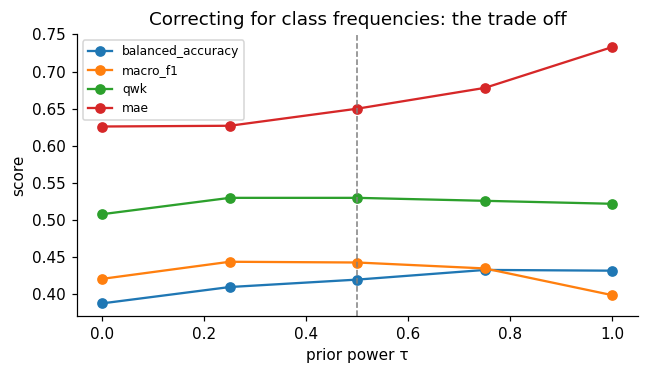

In [61]:
fig, ax = plt.subplots(figsize=(6, 3.5))
taus = [0.0, 0.25, 0.5, 0.75, 1.0]
for metric in ("balanced_accuracy", "macro_f1", "qwk", "mae"):
    ax.plot(taus, trade_off[metric].values, marker="o", label=metric)
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set(xlabel="prior power τ", ylabel="score", title="Correcting for class frequencies: the trade off")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
As τ grows, balanced accuracy rises and MAE gets worse; macro F1 and QWK are flat between 0.25 and 0.5 and drop at 1.
</p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Confirmation on folds that were not used to choose
  </h3>
  <p>
  Choosing among several variants on the same folds used to report them is optimistic (Cawley and Talbot, 2010). We therefore evaluate v1 and the final model again (a) on five new repetitions with seeds never used above, and (b) on the four official folds distributed with LNDb (`trainFolds.csv`, split by CT), which played no part in any decision.
  </p>
  <p>
We'll see that, on the official folds, the final model is better than v1 on all four metrics.
</p>
</div>

In [62]:
make_final = lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES, size_only_column="is_lidc", prior_power=0.5)
make_v1 = lambda: RidgeWithTunedCuts(HANDCRAFTED)

confirm = {}
confirm["v1 (new seeds)"] = evaluate("v1, new seeds", make_v1, repeats=5, first_seed=100)
confirm["final (new seeds)"] = evaluate("final, new seeds", make_final, use_lidc=True, repeats=5, first_seed=100)
print("composite, final minus v1 (new seeds):", paired_difference(y, groups, oof["v1, new seeds"], oof["final, new seeds"]))

official = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainFolds.csv")
def official_fold_predictions(make_model, use_lidc):
    predicted = np.zeros(len(lndb), dtype=int)
    for column in official.columns:
        test_scans = official[column].dropna().astype(int).map("LNDb-{:04d}".format)
        is_test = lndb.scan_id.isin(test_scans).to_numpy()
        train = pd.concat([lndb[~is_test], data[~is_lndb]]) if use_lidc else lndb[~is_test]
        predicted[is_test] = make_model().fit(train, train.rating.to_numpy()).predict(lndb[is_test])
    return [predicted]
confirm["v1 (official folds)"] = summarise(y, groups, official_fold_predictions(make_v1, False))["mean"]
confirm["final (official folds)"] = summarise(y, groups, official_fold_predictions(make_final, True))["mean"]
pd.DataFrame(confirm).T

composite, final minus v1 (new seeds): {'difference': np.float64(0.07), 'ci_low': np.float64(-0.059), 'ci_high': np.float64(0.2)}


,balanced_accuracy,macro_f1,qwk,mae,composite
v1 (new seeds),0.431,0.405,0.517,0.722,0.631
final (new seeds),0.404,0.425,0.526,0.653,0.702
v1 (official folds),0.398,0.384,0.519,0.714,0.587
final (official folds),0.411,0.429,0.533,0.654,0.720


In [64]:
final_oof = oof["final, new seeds"]
rng = np.random.default_rng(0)
draws = []
for _ in range(3000):
    rows = rng.choice(len(y), 55, replace=False)
    draws.append(competition_metrics(y[rows], final_oof[rng.integers(len(final_oof))][rows]))
draws = pd.DataFrame(draws)
draws.describe(percentiles=[0.025, 0.975]).loc[["mean", "std", "2.5%", "97.5%"]].round(3)

,balanced_accuracy,macro_f1,qwk,mae
mean,0.411,0.401,0.511,0.656
std,0.089,0.090,0.109,0.092
2.5%,0.258,0.252,0.281,0.473
97.5%,0.601,0.596,0.704,0.836


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Errors, subgroups, and what the model looks at
  </h3>
</div>

In [65]:
prediction = final_oof[0]
print("Confusion matrix (rows: true rating 1..5, columns: predicted 1..5)")
print(confusion_matrix(y, prediction, labels=range(1, 6)))
extra = pd.Series(all_metrics(y, prediction)).round(3)
extra[["within_one", "sensitivity_4_5", "recall_1", "recall_2", "recall_3", "recall_4", "recall_5"]]

Confusion matrix (rows: true rating 1..5, columns: predicted 1..5)
[[122  68  19   4   0]
 [ 45 138  56  14   1]
 [ 20  89  79  21   0]
 [  4  13  30  24   0]
 [  0   3   4   7   4]]


within_one         0.893
sensitivity_4_5    0.393
recall_1           0.573
recall_2           0.543
recall_3           0.378
recall_4           0.338
recall_5           0.222
dtype: float64

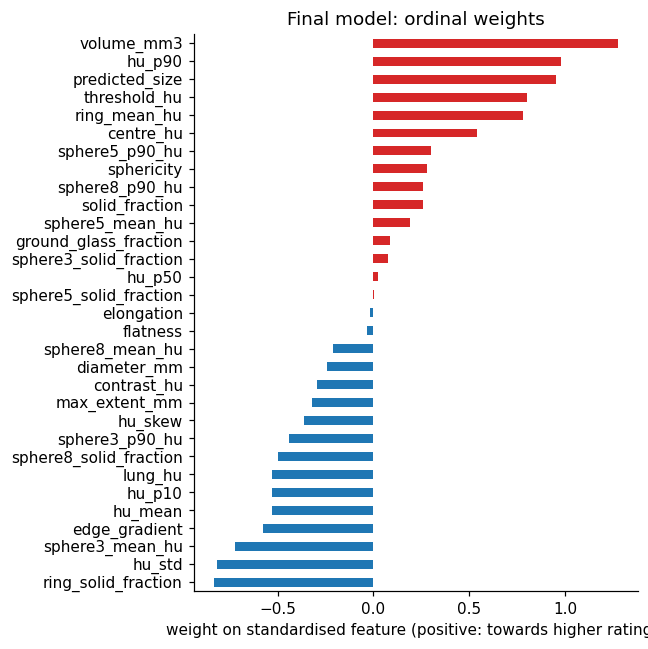

In [68]:
final_model = make_final().fit(data, data.rating.to_numpy())
ordinal = final_model.model_.named_steps["ordinallogisticregression"]
weights = pd.Series(ordinal.coef_, index=FEATURES + ["predicted_size"]).sort_values()
fig, ax = plt.subplots(figsize=(6, 6))
weights.plot.barh(ax=ax, color=["tab:blue" if w < 0 else "tab:red" for w in weights])
ax.set(xlabel="weight on standardised feature (positive: towards higher ratings)", title="Final model: ordinal weights")
plt.tight_layout(); plt.show()

In [69]:
# Permutation importance: how much the composite drops when one feature is shuffled in held out folds
composite_scorer = lambda model, X, target: all_metrics(target, model.predict(X))["composite"]
importances = []
for train, test in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(lndb, y, groups):
    rows = pd.concat([lndb.iloc[train], data[~is_lndb]])
    model = make_final().fit(rows, rows.rating.to_numpy())
    result = permutation_importance(model, lndb.iloc[test][FEATURES], y[test], scoring=composite_scorer, n_repeats=5,
                                    random_state=0)
    importances.append(pd.Series(result.importances_mean, index=FEATURES))
importance = pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False)
importance.head(10).round(3)

volume_mm3             0.509
threshold_hu           0.460
ring_mean_hu           0.409
hu_std                 0.393
ring_solid_fraction    0.358
hu_p90                 0.321
centre_hu              0.296
hu_skew                0.253
lung_hu                0.209
sphere5_mean_hu        0.171
dtype: float64

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The weights and the permutation importance tell the same story: size (the volume of our mask and the predicted size, whose weights share the same information) and the density of the nodule and of its surroundings carry most of the signal, which is what radiologists use (size, solid or ground glass, calcification). Permutation importance is computed on held out folds and with the competition composite, so it measures what each feature contributes to our actual objective (Molnar, 2022, gives a readable account of both methods). Correlated features share their importance, so small values must not be read as "useless".
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   1-to-3 scale for the report
  </h3>
  <p>
    As a complement we decided to also set the ratings to a 1 to 3 scale in order to be more adequate to the clinical procedure. With this results the communication with the clinical body is easier since knowing exactly if a nodule is considered to be Benign or Malign is exactly what they expect to know and to address. Benign (ratings 1 and 2), indeterminate (3) and suspicious (4 and 5).
  </p>
</div>

In [70]:
to_three = lambda rating: np.digitize(rating, [2.5, 3.5]) + 1
three_true, three_pred = to_three(y), to_three(prediction)
from sklearn.metrics import balanced_accuracy_score, f1_score, mean_absolute_error
pd.Series({"balanced_accuracy": balanced_accuracy_score(three_true, three_pred),
           "macro_f1": f1_score(three_true, three_pred, average="macro"),
           "qwk": cohen_kappa_score(three_true, three_pred, weights="quadratic"),
           "mae": mean_absolute_error(three_true, three_pred)}).round(3)

balanced_accuracy    0.523
macro_f1             0.532
qwk                  0.444
mae                  0.414
dtype: float64

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Submission
  </h3>
  <p>
The final model is trained on all 765 LNDb nodules (classifier and size model) and all 2621 LIDC nodules (size model only), and predicts every test candidate as if it were a nodule. The five candidates of CT 286 whose centre falls outside the scan have no patch; their features are missing and the model fills them with the training medians, like any missing value. 
</p>
</div>

In [71]:
test_rows = pd.read_csv(LNDB_DIR / "testNodules.csv")
test_rows["patch_id"] = [f"LNDb-{int(c):04d}_f{int(f):03d}" for c, f in zip(test_rows.LNDbID, test_rows.FindingID)]
test = test_rows.merge(features[features.split == "test"].drop(columns="split"), on="patch_id", how="left")
test["is_lidc"], test["batch"] = 0, "LNDb"

submission = test_rows[["LNDbID", "FindingID", "x", "y", "z"]].copy()
submission["prediction"] = final_model.predict(test).astype(int)
check_submission(submission, test_rows)

previous = REPO_ROOT / "reports" / "predictions.csv"
backup = REPO_ROOT / "reports" / "predictions_v1_ridge.csv"
if previous.exists() and not backup.exists():
    shutil.copy(previous, backup)
submission.to_csv(previous, index=False)
print("saved", previous.relative_to(REPO_ROOT), "|", len(submission), "rows")
pd.DataFrame({"training labels (LNDb)": pd.Series(y).value_counts(normalize=True).sort_index(),
              "all test candidates": submission.prediction.value_counts(normalize=True).sort_index(),
              "v1, all test candidates": pd.read_csv(backup).prediction.value_counts(normalize=True).sort_index()}).round(3)

saved reports/predictions.csv | 2900 rows


,training labels (LNDb),all test candidates,"v1, all test candidates"
1,0.278,0.050,0.072
2,0.332,0.293,0.382
3,0.273,0.481,0.221
4,0.093,0.169,0.319
5,0.024,0.006,0.006


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    References
  </h1>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Ambroise, C. and McLachlan, G. J. (2002). Selection bias in gene extraction on the basis of microarray gene expression data. <i>PNAS</i>, 99(10), 6562 to 6566.</li>
    <li style="margin-bottom: 8px;">Armato, S. G. III et al. (2011). The Lung Image Database Consortium (LIDC) and Image Database Resource Initiative (IDRI). <i>Medical Physics</i>, 38(2), 915 to 931.</li>
    <li style="margin-bottom: 8px;">Baltatzis, V. et al. (2021). The pitfalls of sample selection: a case study on lung nodule classification. arXiv:2108.05386.</li>
    <li style="margin-bottom: 8px;">Blum, A. and Hardt, M. (2015). The Ladder: a reliable leaderboard for machine learning competitions. <i>ICML</i>.</li>
    <li style="margin-bottom: 8px;">Cawley, G. C. and Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. <i>JMLR</i>, 11, 2079 to 2107.</li>
    <li style="margin-bottom: 8px;">Collins, G. S. et al. (2024). TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. <i>BMJ</i>, 385, e078378.</li>
    <li style="margin-bottom: 8px;">Danielsson, P.-E. (1980). Euclidean distance mapping. Computer Graphics and Image Processing, 14(3), 227 to 248.</li>
    <li style="margin-bottom: 8px;">Dice, L. R. (1945). Measures of the amount of ecologic association between species. <i>Ecology</i>, 26(3), 297 to 302.</li>
    <li style="margin-bottom: 8px;">Dou, Q., Chen, H., Yu, L., Qin, J. and Heng, P.-A. (2017). Multilevel contextual 3-D CNNs for false positive reduction in pulmonary nodule detection. <i>IEEE Transactions on Biomedical Engineering</i>, 64(7), 1558 to 1567.</li>
    <li style="margin-bottom: 8px;">Dwork, C. et al. (2015). The reusable holdout: preserving validity in adaptive data analysis. <i>Science</i>, 349(6248), 636 to 638.</li>
    <li style="margin-bottom: 8px;">Field, C. A. and Welsh, A. H. (2007). Bootstrapping clustered data. <i>Journal of the Royal Statistical Society B</i>, 69(3), 369 to 390.</li>
    <li style="margin-bottom: 8px;">Gneiting, T. (2011). Making and evaluating point forecasts. <i>Journal of the American Statistical Association</i>, 106(494), 746 to 762.</li>
    <li style="margin-bottom: 8px;">Gonzalez, R. C. and Woods, R. E. (2018). Digital Image Processing (4th ed.). Pearson.</li>
    <li style="margin-bottom: 8px;">Hansell, D. M. et al. (2008). Fleischner Society: glossary of terms for thoracic imaging. <i>Radiology</i>, 246(3), 697 to 722.</li>
    <li style="margin-bottom: 8px;">Johnson, W. E., Li, C. and Rabinovic, A. (2007). Adjusting batch effects in microarray expression data using empirical Bayes methods. <i>Biostatistics</i>, 8(1), 118 to 127.</li>
    <li style="margin-bottom: 8px;">Koo, T. K. and Li, M. Y. (2016). A guideline of selecting and reporting intraclass correlation coefficients for reliability research. <i>Journal of Chiropractic Medicine</i>, 15(2), 155 to 163.</li>
    <li style="margin-bottom: 8px;">Kostis, W. J., Reeves, A. P., Yankelevitz, D. F. and Henschke, C. I. (2003). Three-dimensional segmentation and growth-rate estimation of small pulmonary nodules in helical CT images. <i>IEEE Transactions on Medical Imaging</i>, 22(10), 1259 to 1274.</li>
    <li style="margin-bottom: 8px;">Kuhnigk, J.-M. et al. (2006). Morphological segmentation and partial volume analysis for volumetry of solid pulmonary lesions in thoracic CT scans. <i>IEEE Transactions on Medical Imaging</i>, 25(4), 417 to 434.</li>
    <li style="margin-bottom: 8px;">Lambin, P. et al. (2017). Radiomics: the bridge between medical imaging and personalized medicine. <i>Nature Reviews Clinical Oncology</i>, 14, 749 to 762.</li>
    <li style="margin-bottom: 8px;">MacMahon, H. et al. (2017). Guidelines for management of incidental pulmonary nodules detected on CT images: from the Fleischner Society 2017. <i>Radiology</i>, 284(1), 228 to 243.</li>
    <li style="margin-bottom: 8px;">McCullagh, P. (1980). Regression models for ordinal data. <i>Journal of the Royal Statistical Society B</i>, 42(2), 109 to 142.</li>
    <li style="margin-bottom: 8px;">Molnar, C. (2022). Interpretable Machine Learning (2nd ed.). christophm.github.io/interpretable-ml-book.</li>
    <li style="margin-bottom: 8px;">Mongan, J., Moy, L. and Kahn, C. E. (2020). Checklist for Artificial Intelligence in Medical Imaging (CLAIM). <i>Radiology: Artificial Intelligence</i>, 2(2), e200029.</li>
    <li style="margin-bottom: 8px;">Orlhac, F. et al. (2022). A guide to ComBat harmonization of imaging biomarkers in multicenter studies. <i>Journal of Nuclear Medicine</i>, 63(2), 172 to 179.</li>
    <li style="margin-bottom: 8px;">Pai, S. et al. (2024). Foundation model for cancer imaging biomarkers. <i>Nature Machine Intelligence</i>.</li>
    <li style="margin-bottom: 8px;">Pedrosa, J. et al. (2019). LNDb: a lung nodule database on computed tomography. arXiv:1911.08434.</li>
    <li style="margin-bottom: 8px;">PyRadiomics documentation, Customization (resampling and interpolators).</li>
    <li style="margin-bottom: 8px;">Regulation (EU) 2016/679 (GDPR); Regulation (EU) 2017/745 (MDR); Regulation (EU) 2024/1689 (AI Act).</li>
    <li style="margin-bottom: 8px;">Saerens, M., Latinne, P. and Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: a simple procedure. <i>Neural Computation</i>, 14(1), 21 to 41.</li>
    <li style="margin-bottom: 8px;">Setio, A. A. A. et al. (2016). Pulmonary nodule detection in CT images: false positive reduction using multi-view convolutional networks. <i>IEEE Transactions on Medical Imaging</i>, 35(5), 1160 to 1169.</li>
    <li style="margin-bottom: 8px;">Setio, A. A. A. et al. (2017). Validation, comparison, and combination of algorithms for automatic detection of pulmonary nodules in computed tomography images: the LUNA16 challenge. <i>Medical Image Analysis</i>.</li>
    <li style="margin-bottom: 8px;">Shafiq-ul-Hassan, M. et al. (2017). Intrinsic dependencies of CT radiomic features on voxel size and number of gray levels. <i>Medical Physics</i>, 44(3), 1050 to 1062.</li>
    <li style="margin-bottom: 8px;">Shrout, P. E. and Fleiss, J. L. (1979). Intraclass correlations: uses in assessing rater reliability. <i>Psychological Bulletin</i>, 86(2), 420 to 428.</li>
    <li style="margin-bottom: 8px;">Tejani, A. S. et al. (2024). Checklist for Artificial Intelligence in Medical Imaging (CLAIM): 2024 update. <i>Radiology: Artificial Intelligence</i>.</li>
    <li style="margin-bottom: 8px;">Traverso, A. et al. (2018). Repeatability and reproducibility of radiomic features: a systematic review. <i>International Journal of Radiation Oncology, Biology, Physics</i>, 102(4), 1143 to 1158.</li>
    <li style="margin-bottom: 8px;">van Griethuysen, J. J. M. et al. (2017). Computational radiomics system to decode the radiographic phenotype. <i>Cancer Research</i>, 77(21), e104 to e107.</li>
    <li style="margin-bottom: 8px;">Vapnik, V. and Vashist, A. (2009). A new learning paradigm: learning using privileged information. <i>Neural Networks</i>, 22(5 to 6), 544 to 557.</li>
    <li style="margin-bottom: 8px;">Varoquaux, G. (2018). Cross-validation failure: small sample sizes lead to large error bars. <i>NeuroImage</i>, 180, 68 to 77.</li>
    <li style="margin-bottom: 8px;">Wolpert, D. H. (1992). Stacked generalization. <i>Neural Networks</i>, 5(2), 241 to 259.</li>
    <li style="margin-bottom: 8px;">Zhang, Y., Jenkins, D. F., Manimaran, S. and Johnson, W. E. (2018). Alternative empirical Bayes models for adjusting for batch effects in genomic studies. <i>BMC Bioinformatics</i>, 19, 262.</li>
    <li style="margin-bottom: 8px;">Zwanenburg, A. et al. (2019). Assessing robustness of radiomic features by image perturbation. <i>Scientific Reports</i>, 9, 614.</li>
    <li style="margin-bottom: 8px;">Zwanenburg, A. et al. (2020). The Image Biomarker Standardization Initiative: standardized quantitative radiomics for high-throughput image-based phenotyping. <i>Radiology</i>, 295(2), 328 to 338.</li>
  </ul>
</div>